# Preparación y análisis exploratorio de los datos

En este primer notebook prepararemos los datos de ventas semanales de Walmart y exploraremos sus principales características. El objetivo es entender qué información tenemos, qué limitaciones presenta y qué aspectos conviene tener en cuenta para luego construir los modelos predictivos.

El contenido del notebook abarca desde la carga y el tratamiento de valores ausentes hasta el análisis de las ventas, las campañas y la continuidad de las series. Por último, exportaremos los datframes que tomaremos como punto de partida del segundo notebook.

Visto a posteriori, las observaciones del análisis orientan el trabajo, pero no implican por sí solas que se hayan realizado todas las pruebas que se plantearon durante la exploración. No es extraño que alguna observación no se haya acabado realizando, ya que con el avance del trabajo se ha cambiado de opinión o simplemente no se ha visto necesario.

## 1. Descripción de los datos

El siguiente dataset ha sido obtenido de una competición realizada en kaggle. Como punto de referencia, utilizaremos los objetivos de esta para conocer los puntos fuertes y flacos de este dataset. Esta descripición está basada en el `README` adjunto

El dataset proporciona datos históricos de ventas correspondientes a **45 tiendas Walmart** ubicadas en distintas regiones. Cada tienda contiene varios departamentos y el objetivo consiste en predecir las ventas semanales de cada departamento para cada tienda.

Además, Walmart realiza varias campañas promocionales de descuentos, denominadas **markdowns**, a lo largo del año. Estas promociones suelen preceder a festividades importantes, entre las que destacan:

* Super Bowl
* Labor Day
* Thanksgiving
* Christmas

Siguiendo la línea de la competición, las semanas que incluyen alguna de estas festividades tendrán un peso **cinco veces mayor** en la evaluación que las semanas normales. Esto se debe a que el número de ventas estas semanas es mucho más grande y, por tanto, es primordial que el modelo funcione bien en estas semanas.

Una de las principales dificultades de la competición consiste en modelar correctamente el efecto de los descuentos promocionales durante estas semanas festivas, especialmente porque no se dispone de datos históricos completos o ideales.

---

### `stores.csv`

Este archivo contiene información anonimizada sobre las **45 tiendas**, incluyendo:

* El tipo de tienda.
* El tamaño de la tienda.

---

### `train.csv`

Este archivo contiene los datos históricos utilizados para el entrenamiento del modelo.

El periodo temporal abarca desde el **5 de febrero de 2010** hasta el **26 de octubre de 2012**.

Incluye las siguientes variables:

| Variable       | Descripción                                                              |
| -------------- | ------------------------------------------------------------------------ |
| `Store`        | Número identificador de la tienda.                                       |
| `Dept`         | Número identificador del departamento.                                   |
| `Date`         | Semana correspondiente al registro.                                      |
| `Weekly_Sales` | Ventas semanales del departamento indicado en la tienda correspondiente. |
| `IsHoliday`    | Indica si la semana está marcada como festiva en el conjunto de datos.                     |

---

### `test.csv`

Este archivo tiene la misma estructura que `train.csv`, pero no incluye la variable `Weekly_Sales`.

El objetivo es predecir las ventas para cada combinación de:

* `Store`
* `Dept`
* `Date`

---

### `features.csv`

Este archivo contiene información adicional por tienda y fecha. Estas variables se incorporan después a las observaciones de cada departamento.

Incluye las siguientes variables:

| Variable       | Descripción                                                                              |
| -------------- | ---------------------------------------------------------------------------------------- |
| `Store`        | Número identificador de la tienda.                                                       |
| `Date`         | Semana correspondiente al registro.                                                      |
| `Temperature`  | Temperatura media de la región.                                                          |
| `Fuel_Price`   | Precio del combustible en la región.                                                     |
| `MarkDown1-5`  | Datos anonimizados relacionados con las promociones y descuentos realizados por Walmart. |
| `CPI`          | Índice de precios al consumo.                                                            |
| `Unemployment` | Tasa de desempleo.                                                                       |
| `IsHoliday`    | Indica si la semana incluye una festividad especial.                                     |

> **Nota sobre `MarkDown1-5`:**
> Los datos de estas variables solo están disponibles a partir de noviembre de 2011 y no existen para todas las tiendas ni para todas las fechas. Los valores ausentes aparecen representados mediante `NA`.

## 2. Entorno y descarga de los datos

El notebook está hecho y preparado para Google Colab: utiliza Google Drive para guardar los datos procesados y las credenciales de Kaggle para descargar los archivos.

Primero preparamos el entorno y después cargamos las cuatro tablas de datos y el ejemplo de envío de predicciones.

In [1]:
!pip uninstall -y kaggle kagglesdk
!pip install -q --upgrade kaggle

Found existing installation: kaggle 2.0.2
Uninstalling kaggle-2.0.2:
  Successfully uninstalled kaggle-2.0.2
Found existing installation: kagglesdk 0.1.37
Uninstalling kagglesdk-0.1.37:
  Successfully uninstalled kagglesdk-0.1.37
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.5/262.5 kB 7.6 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path
import pandas as pd

import zipfile
from google.colab import files, drive
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
# =============================================================================
# CONTROL GLOBAL DE REGENERACIÓN DE DATASETS
# =============================================================================
# TRAIN=True: reconstruir y sobrescribir los parquet procesados.
# TRAIN=False: cargar los parquet existentes si su origen no ha cambiado;
#              regenerar si faltan o si han cambiado los datos brutos.
# No hay modelos de aprendizaje automático en este notebook.
TRAIN = True
print(f"Modo de preparación del EDA: TRAIN = {TRAIN}")


Modo de preparación del EDA: TRAIN = True


In [4]:
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import subprocess


def download_competition_from_kaggle(
    competition_name,
    output_dir="competition_data",
    force_download=False,
    remove_zip=False
):
    """
    Descarga y descomprime los archivos de una competición de Kaggle.

    Parámetros
    ----------
    competition_name : str
        Identificador de la competición. Es la última parte de su URL.

        Ejemplo:
        https://www.kaggle.com/competitions/titanic
        competition_name = "titanic"

    output_dir : str
        Carpeta donde se descargarán y descomprimirán los datos.

    force_download : bool
        Si es True, fuerza la descarga aunque el archivo ya exista.

    remove_zip : bool
        Si es True, elimina los archivos ZIP después de descomprimirlos.
    """

    # -------------------------------------------------------------------------
    # 1. CONFIGURACIÓN DE LAS CREDENCIALES
    # -------------------------------------------------------------------------

    kaggle_dir = Path("/root/.kaggle")
    kaggle_dir.mkdir(parents=True, exist_ok=True)

    kaggle_json_path = kaggle_dir / "kaggle.json"

    if not kaggle_json_path.exists():

        print("Sube tu archivo kaggle.json:")

        uploaded = files.upload()

        if "kaggle.json" not in uploaded:
            raise FileNotFoundError(
                "No se ha subido un archivo llamado exactamente 'kaggle.json'."
            )

        # Guardamos directamente el contenido subido en la carpeta de Kaggle
        kaggle_json_path.write_bytes(uploaded["kaggle.json"])

        # Permisos seguros
        os.chmod(kaggle_json_path, 0o600)

        print("Archivo kaggle.json configurado correctamente.")

    else:
        print("El archivo kaggle.json ya está configurado.")

    # -------------------------------------------------------------------------
    # 2. CREACIÓN DE LA CARPETA DE SALIDA
    # -------------------------------------------------------------------------

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    # -------------------------------------------------------------------------
    # 3. DESCARGA DE LA COMPETICIÓN
    # -------------------------------------------------------------------------

    command = [
        "kaggle",
        "competitions",
        "download",
        competition_name,
        "--path",
        str(output_path)
    ]

    if force_download:
        command.append("--force")

    print(f"Descargando competición: {competition_name}")

    try:
        subprocess.run(command, check=True)

    except subprocess.CalledProcessError as error:
        raise RuntimeError(
            "No se pudo descargar la competición. Comprueba que:\n"
            "1. El nombre de la competición sea correcto.\n"
            "2. Te hayas unido a la competición.\n"
            "3. Hayas aceptado sus reglas.\n"
            "4. El archivo kaggle.json sea válido."
        ) from error

    # -------------------------------------------------------------------------
    # 4. BÚSQUEDA DE ARCHIVOS ZIP
    # -------------------------------------------------------------------------

    zip_files = list(output_path.glob("*.zip"))

    if not zip_files:
        print(
            "No se encontró ningún ZIP en la carpeta principal. "
            "Es posible que Kaggle haya descargado los archivos directamente."
        )

    # -------------------------------------------------------------------------
    # 5. DESCOMPRESIÓN
    # -------------------------------------------------------------------------

    for zip_path in zip_files:

        if not zipfile.is_zipfile(zip_path):
            print(f"Se omite {zip_path.name}: no es un ZIP válido.")
            continue

        print(f"Descomprimiendo: {zip_path.name}")

        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(output_path)

        if remove_zip:
            zip_path.unlink()
            print(f"ZIP eliminado: {zip_path.name}")

    # -------------------------------------------------------------------------
    # 6. RESULTADO
    # -------------------------------------------------------------------------

    downloaded_files = sorted(
        path.relative_to(output_path)
        for path in output_path.rglob("*")
        if path.is_file()
    )

    print(f"\nProceso finalizado. Datos disponibles en: {output_path.resolve()}")
    print(f"Número de archivos encontrados: {len(downloaded_files)}")

    return str(output_path)

In [6]:
data_dir = download_competition_from_kaggle(
    competition_name="walmart-recruiting-store-sales-forecasting",
    output_dir="walmart_sales"
)

Sube tu archivo kaggle.json:


Saving kaggle.json to kaggle.json
Archivo kaggle.json configurado correctamente.
Descargando competición: walmart-recruiting-store-sales-forecasting
Descomprimiendo: walmart-recruiting-store-sales-forecasting.zip

Proceso finalizado. Datos disponibles en: /content/walmart_sales
Número de archivos encontrados: 6


In [7]:
data_path = Path(data_dir)

train = pd.read_csv(data_path / "train.csv.zip")
test = pd.read_csv(data_path / "test.csv.zip")
features = pd.read_csv(data_path / "features.csv.zip")
stores = pd.read_csv(data_path / "stores.csv")
sample_submission = pd.read_csv(data_path / "sampleSubmission.csv.zip")

## 3. Preparación de los datos

En esta sección vamos a revisar la estructura de los dataframes, los valores ausentes y el formato de las variables. Conservaremos las observaciones originales y preparamos la información necesaria para el análisis.

In [8]:
print('--- Training Data Info ---')
train.info()
print('\n--- Test Data Info ---')
test.info()
print('\n--- Features Data Info ---')
features.info()
print('\n--- Stores Data Info ---')
stores.info()

--- Training Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB

--- Test Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115064 entries, 0 to 115063
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Store      115064 non-null  int64 
 1   Dept       115064 non-null  int64 
 2   Date       115064 non-null  object
 3   IsHoliday  115064 non-null  bool  
dtypes: bool(1), int64(2), object(1)
memory usage: 2.7+ MB

--- Features Data Info ---
<class 'pandas.core.fr

### 3.1. Fechas y cobertura temporal

Al trabajar con fechas, es imprescindible convertir la variable `Date` al formato temporal de pandas en `train`, `test` y `features`. Así podremos comparar periodos y, más adelante, construir retardos respetando la distancia real entre semanas de una forma mucho más óptima.

In [9]:
train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])
features['Date'] = pd.to_datetime(features['Date'])

print("Date columns converted to datetime type.")

Date columns converted to datetime type.


In [10]:
# Rango temporal del dataset

# Entrenamiento
fecha_inicio_train = train['Date'].min()
fecha_fin_train = train['Date'].max()

# Test
fecha_inicio_test = test['Date'].min()
fecha_fin_test = test['Date'].max()

print(f"\nEl rango temporal del DataFrame 'train' es:")
print(f"\nEntrenamiento")
print(f"  Fecha de inicio: {fecha_inicio_train.strftime('%Y-%m-%d')}")
print(f"  Fecha de fin:    {fecha_fin_train.strftime('%Y-%m-%d')}")
print(f"\nTest")
print(f"  Fecha de inicio: {fecha_inicio_test.strftime('%Y-%m-%d')}")
print(f"  Fecha de fin:    {fecha_fin_test.strftime('%Y-%m-%d')}")


El rango temporal del DataFrame 'train' es:

Entrenamiento
  Fecha de inicio: 2010-02-05
  Fecha de fin:    2012-10-26

Test
  Fecha de inicio: 2012-11-02
  Fecha de fin:    2013-07-26


In [11]:
# Solo por asegurar, comprobamos que los rangos temporales coinciden
fecha_inicio_features = features['Date'].min()
fecha_fin_features = features['Date'].max()

print(f"\nEl rango temporal del DataFrame 'features' es:")
print(f"  Fecha de inicio: {fecha_inicio_features.strftime('%Y-%m-%d')}")
print(f"  Fecha de fin:    {fecha_fin_features.strftime('%Y-%m-%d')}")


El rango temporal del DataFrame 'features' es:
  Fecha de inicio: 2010-02-05
  Fecha de fin:    2013-07-26


**Primera revisión**

Las tablas `train`, `test` y `stores` no presentan valores ausentes. En `features`, en cambio, faltan datos en `MarkDown1`-`MarkDown5`, `CPI` y `Unemployment`.

Las variables promocionales solo están disponibles desde noviembre de 2011. Esto puede ser un problema en el entrenamiento del modelo, por lo que vamos a estudiar por separado este problema de cobertura, ya que las ausencias de las variables económicas no tienen necesariamente el mismo origen ni requieren el mismo tratamiento.

### 3.2. Preparación de las variables promocionales

Trabajaremos sobre una copia de `features`. Sustituimos los valores ausentes de los `MarkDown` por cero y conservamos su ausencia original en las columnas `_isna`. Así mantenemos una representación numérica sin perder la distinción entre un cero observado y un dato que no estaba disponible. Esta sustitución no implica que podamos afirmar que no hubo promoción.

In [12]:
markdown_cols = ['MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5']

# features va a quedar intacta
features_processed = features.copy()

for col in markdown_cols:
    features_processed[f'{col}_isna'] = features[col].isna()

features_processed[markdown_cols] = features_processed[markdown_cols].fillna(0)

display(features_processed.head())

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday,MarkDown1_isna,MarkDown2_isna,MarkDown3_isna,MarkDown4_isna,MarkDown5_isna
0,1,2010-02-05,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,False,True,True,True,True,True
1,1,2010-02-12,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,True,True,True,True,True,True
2,1,2010-02-19,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,False,True,True,True,True,True
3,1,2010-02-26,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,False,True,True,True,True,True
4,1,2010-03-05,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,False,True,True,True,True,True


Ahora que las columnas `MarkDown` han sido procesadas para rellenar los `NaN` con 0 y se han creado las columnas indicadoras `_isna`, recalcularemos el análisis de valores faltantes. Para ello, utilizaremos las columnas `_isna` que representan la presencia original de valores nulos.

#### Disponibilidad de los datos promocionales

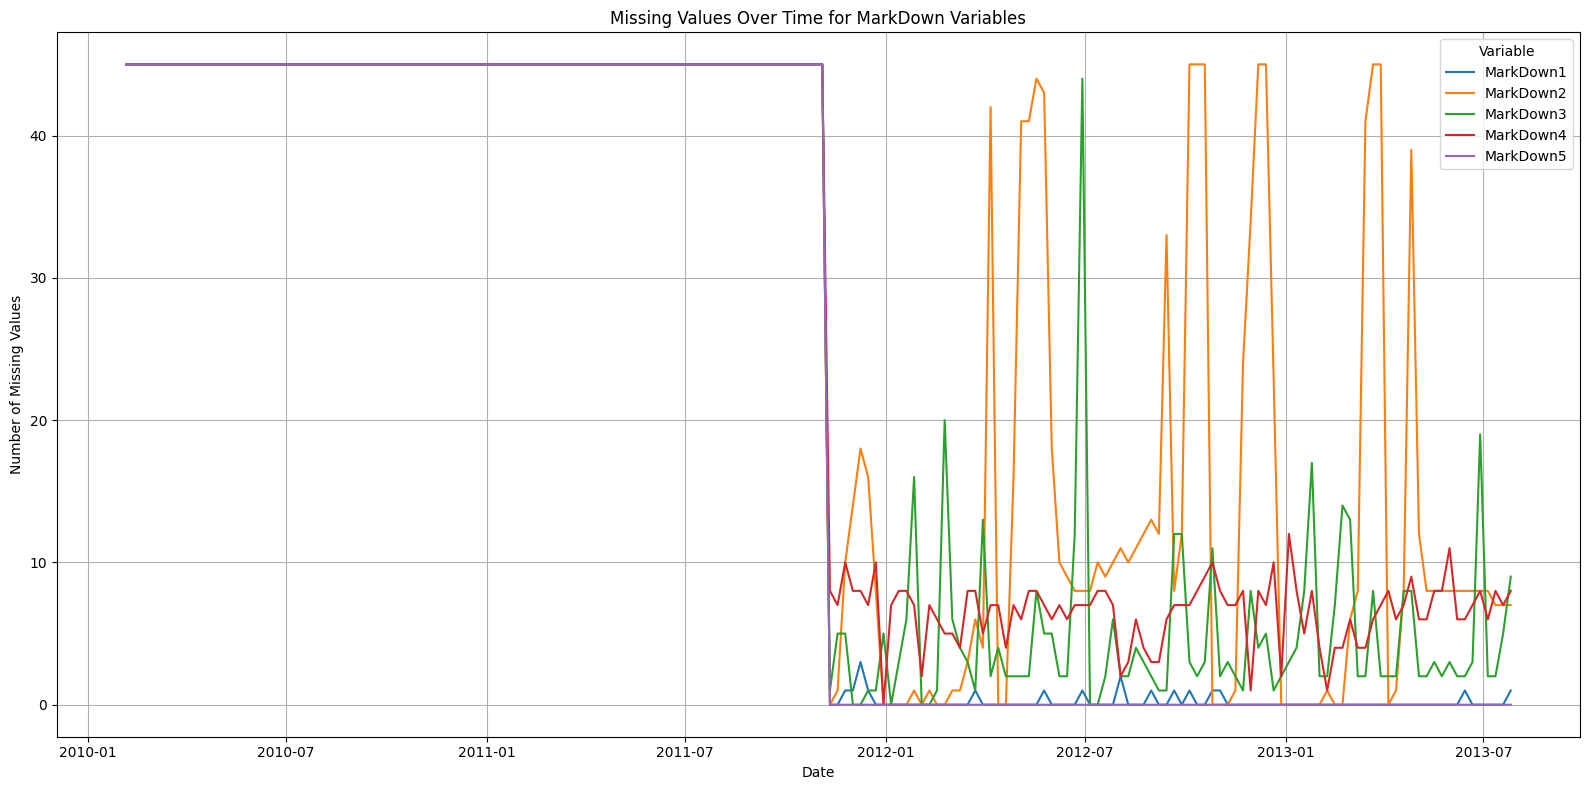

In [13]:
# Creamos el dataframe que vamos a dibujar
markdown_missing_by_date = (
    features_processed
    .groupby('Date')[[f'{col}_isna' for col in markdown_cols]]
    .sum()
    .reset_index()
    .melt(
        id_vars='Date',
        var_name='Variable',
        value_name='Missing_Count'
    )
)

# Eliminamos el '_isna' del nombre de las variables markdown
markdown_missing_by_date['Variable'] = (
    markdown_missing_by_date['Variable']
    .str.replace('_isna', '', regex=False)
)

# Configuración del dibujo
plt.figure(figsize=(16, 8))
sns.lineplot(
    data=markdown_missing_by_date,
    x='Date',
    y='Missing_Count',
    hue='Variable'
)

plt.title('Missing Values Over Time for MarkDown Variables')
plt.xlabel('Date')
plt.ylabel('Number of Missing Values')
plt.grid(True)
plt.legend(title='Variable')
plt.tight_layout()
plt.show()

**Lectura del gráfico**

Cada fecha reúne información de 45 tiendas. Por tanto, 45 valores ausentes indican que ninguna tienda tiene un registro disponible para esa variable; 10 valores ausentes indican que faltan datos en 10 tiendas.

Hasta noviembre de 2011 no hay datos de promociones. A partir de entonces, `MarkDown1` y `MarkDown5` presentan una disponibilidad más estable, mientras que `MarkDown2`, `MarkDown3` y `MarkDown4` muestran más variación. Los valores ausentes, por sí solos, no permiten distinguir entre ausencia de promoción y falta de registro.

Vamos a ampliar el periodo desde noviembre de 2011 y marcar las semanas festivas: Super Bowl en febrero, Labor Day en septiembre, Thanksgiving en noviembre y Christmas en diciembre. Las líneas corresponden a las fechas semanales señaladas por `IsHoliday` en los datos.

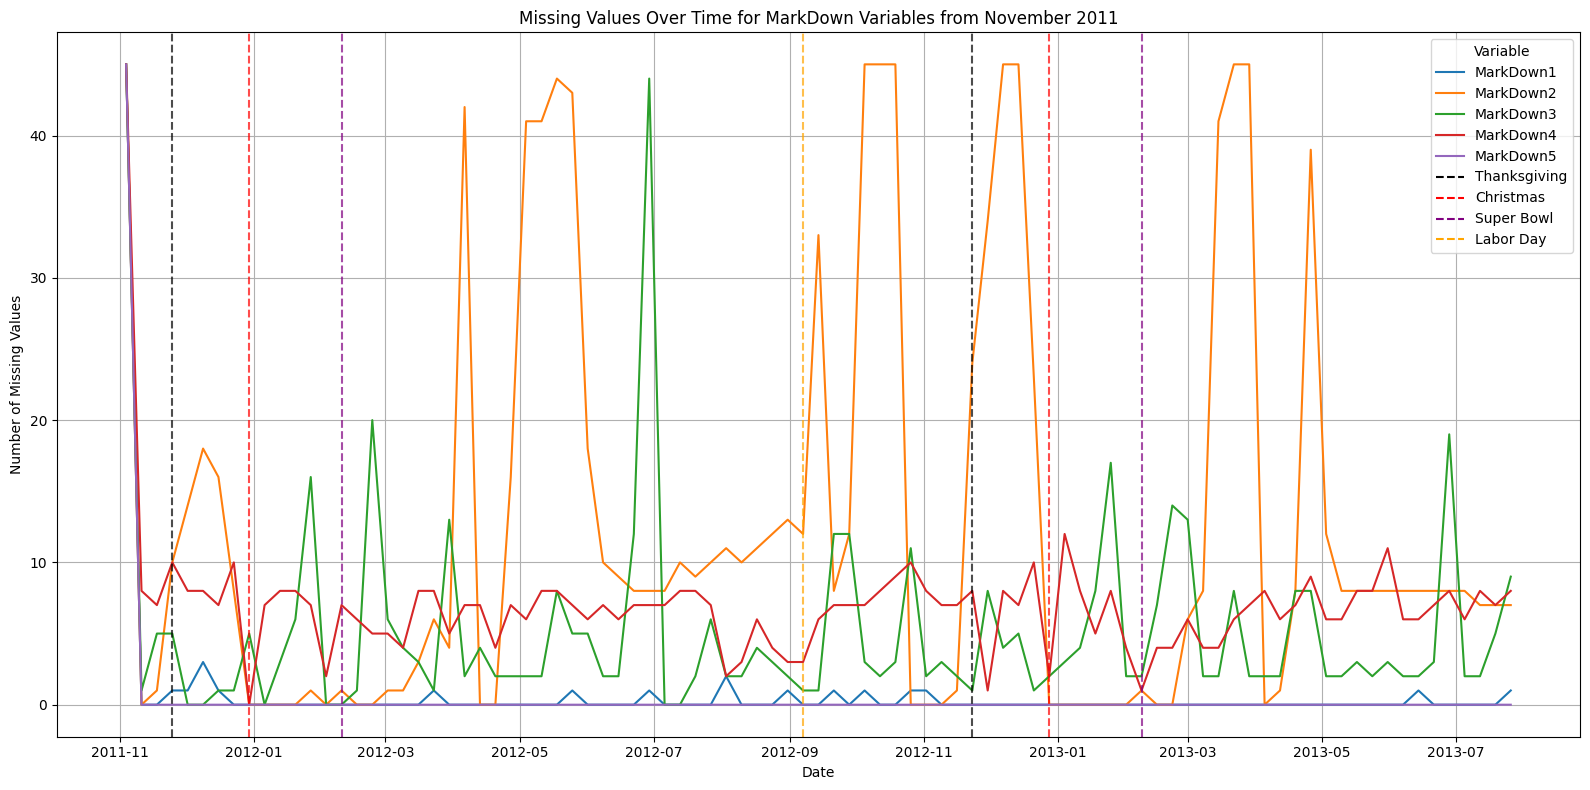

In [14]:
# Fecha a partir de la cual comienzan a registrarse las variables MarkDown
start_date = pd.Timestamp('2011-11-01')

# Filtramos el análisis de valores ausentes para estudiar únicamente
# el periodo en el que los MarkDown ya estaban disponibles en el dataset
markdown_missing_filtered = (
    markdown_missing_by_date[
        markdown_missing_by_date['Date'] >= start_date
    ]
)

# Extraemos las fechas festivas del periodo analizado.
# Como cada fecha aparece repetida para varias tiendas, eliminamos duplicados.
holiday_dates = (
    features_processed.loc[
        (features_processed['IsHoliday']) &
        (features_processed['Date'] >= start_date),
        'Date'
    ]
    .drop_duplicates()
    .sort_values()
)

# Asociamos cada mes con la festividad correspondiente y el color
# que se utilizará para representarla en el gráfico
holiday_info = {
    2:  ('Super Bowl', 'purple'),
    9:  ('Labor Day', 'orange'),
    11: ('Thanksgiving', 'black'),
    12: ('Christmas', 'red')
}


plt.figure(figsize=(16, 8))

# Representamos la evolución temporal del número de valores ausentes
# para cada una de las variables MarkDown
ax = sns.lineplot(
    data=markdown_missing_filtered,
    x='Date',
    y='Missing_Count',
    hue='Variable'
)


# Guardaremos un único elemento de leyenda por tipo de festividad,
# aunque existan varias fechas correspondientes a la misma festividad
holiday_handles = {}
for date in holiday_dates:
    label, color = holiday_info[date.month]

    # Línea vertical en la fecha festiva
    ax.axvline(
        x=date,
        color=color,
        linestyle='--',
        alpha=0.7,
        linewidth=1.5
    )

    # Añadimos el elemento correspondiente a la leyenda únicamente
    # la primera vez que aparece cada festividad
    holiday_handles.setdefault(
        label,
        plt.Line2D(
            [0], [0],
            color=color,
            linestyle='--',
            linewidth=1.5
        )
    )

# Recuperamos los elementos de leyenda generados automáticamente
# por Seaborn para las variables MarkDown
handles, labels = ax.get_legend_handles_labels()

# Combinamos la leyenda de los MarkDown con la de las festividades
ax.legend(
    handles + list(holiday_handles.values()),
    labels + list(holiday_handles.keys()),
    title='Variable'
)

plt.title('Missing Values Over Time for MarkDown Variables from November 2011')
plt.xlabel('Date')
plt.ylabel('Number of Missing Values')
plt.grid(True)
plt.tight_layout()
plt.show()

En el gráfico parece haber una mayor disponibilidad durante algunas semanas festivas. Vamos a comparar los porcentajes de valores ausentes de `MarkDown2`, `MarkDown3` y `MarkDown4` en todo el periodo disponible y en las semanas festivas; después veremos los recuentos por fecha.

In [15]:
# Variables MarkDown con mayor proporción de valores ausentes
markdown_cols_for_table = ['MarkDown2', 'MarkDown3', 'MarkDown4']

# Columnas booleanas que indican si el valor original era NaN
markdown_missing_flags = [f'{col}_isna' for col in markdown_cols_for_table]

# Analizamos únicamente el periodo en el que los MarkDown ya se registraban
markdown_period = features_processed[
    features_processed['Date'] >= start_date
]

# Porcentaje de valores ausentes en todo el periodo
# Como las columnas *_isna son booleanas, su media equivale a la proporción de True
overall_missing = (
    markdown_period[markdown_missing_flags]
    .mean()
    .mul(100)
)

# Porcentaje de valores ausentes únicamente durante semanas festivas
holiday_missing = (
    markdown_period.loc[
        markdown_period['IsHoliday'],
        markdown_missing_flags
    ]
    .mean()
    .mul(100)
)

# Creamos una tabla comparativa y recuperamos los nombres originales de MarkDown
comparison_df = pd.DataFrame({
    'Overall_Missing_Percentage': overall_missing.values,
    'Holiday_Missing_Percentage': holiday_missing.values
}, index=markdown_cols_for_table)

comparison_df.index.name = 'MarkDown_Variable'

display(comparison_df)

,Overall_Missing_Percentage,Holiday_Missing_Percentage
MarkDown_Variable,,
MarkDown2,28.669109,15.238095
MarkDown3,11.770452,5.079365
MarkDown4,15.409035,9.841270


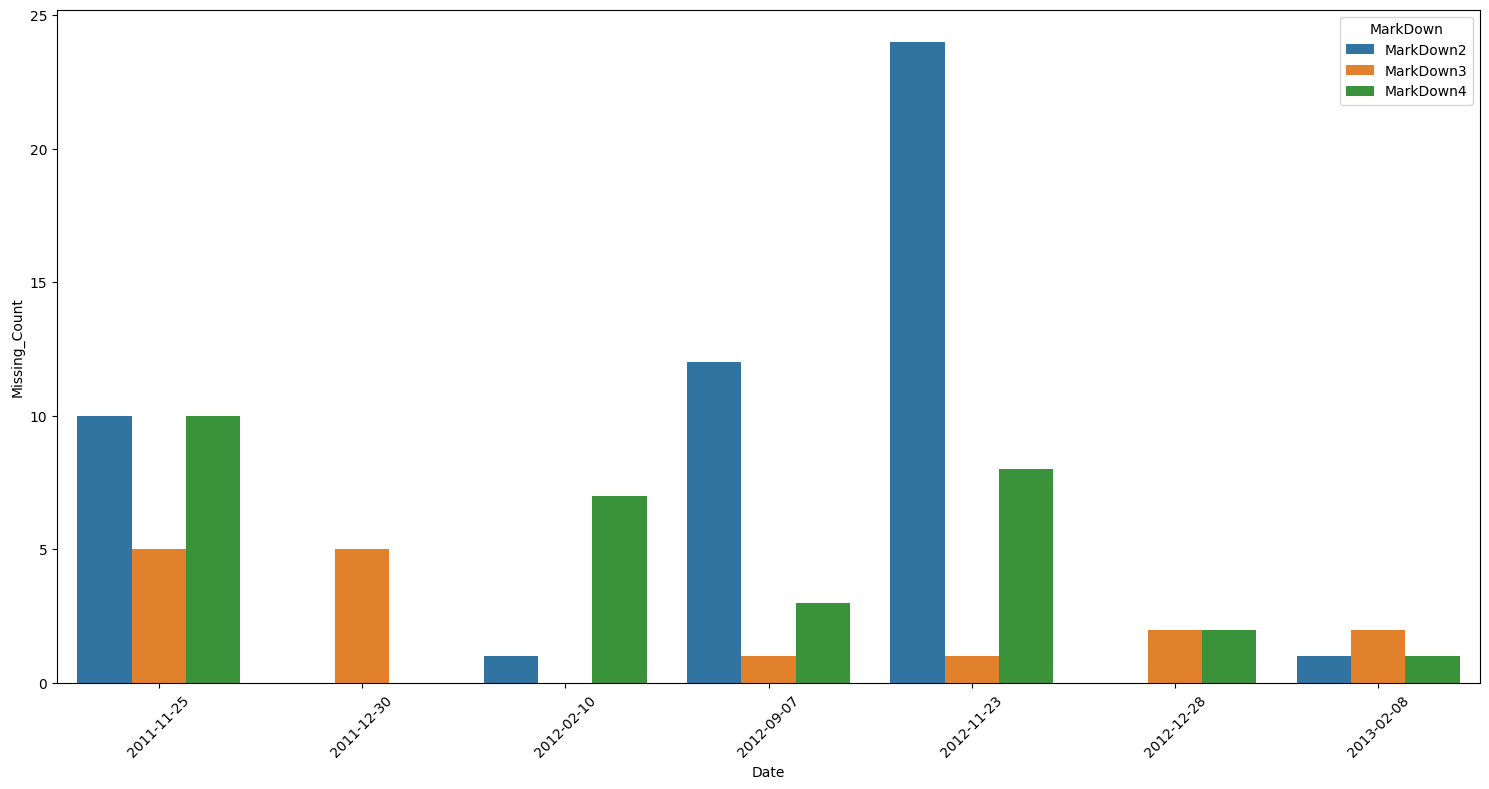

In [16]:
# Seleccionamos las semanas festivas y las variables MarkDown que queremos analizar
holiday_missing = features_processed.loc[
    (features_processed['Date'] >= start_date) & features_processed['IsHoliday'],
    ['Date'] + markdown_missing_flags
]

# Contamos los valores ausentes por fecha y preparamos los datos para Seaborn
holiday_missing = (
    holiday_missing
    .groupby('Date').sum()
    .rename(columns=lambda x: x.replace('_isna', ''))
    .reset_index()
    .melt('Date', var_name='MarkDown', value_name='Missing_Count')
)

plt.figure(figsize=(15, 8))

sns.barplot(
    data=holiday_missing,
    x='Date',
    y='Missing_Count',
    hue='MarkDown'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Las tres variables presentan un menor porcentaje de valores ausentes durante las semanas festivas que en el conjunto del periodo analizado. `MarkDown2` sigue siendo la que tiene más ausencias en ambas comparaciones, aunque su disponibilidad varía bastante entre festividades.

Esta comparación describe la disponibilidad de los registros. No permite concluir que todas las tiendas aplicaran un descuento ni atribuir las ausencias a descuidos de registro.

### 3.3. Disponibilidad de `CPI` y `Unemployment`

**CPI**

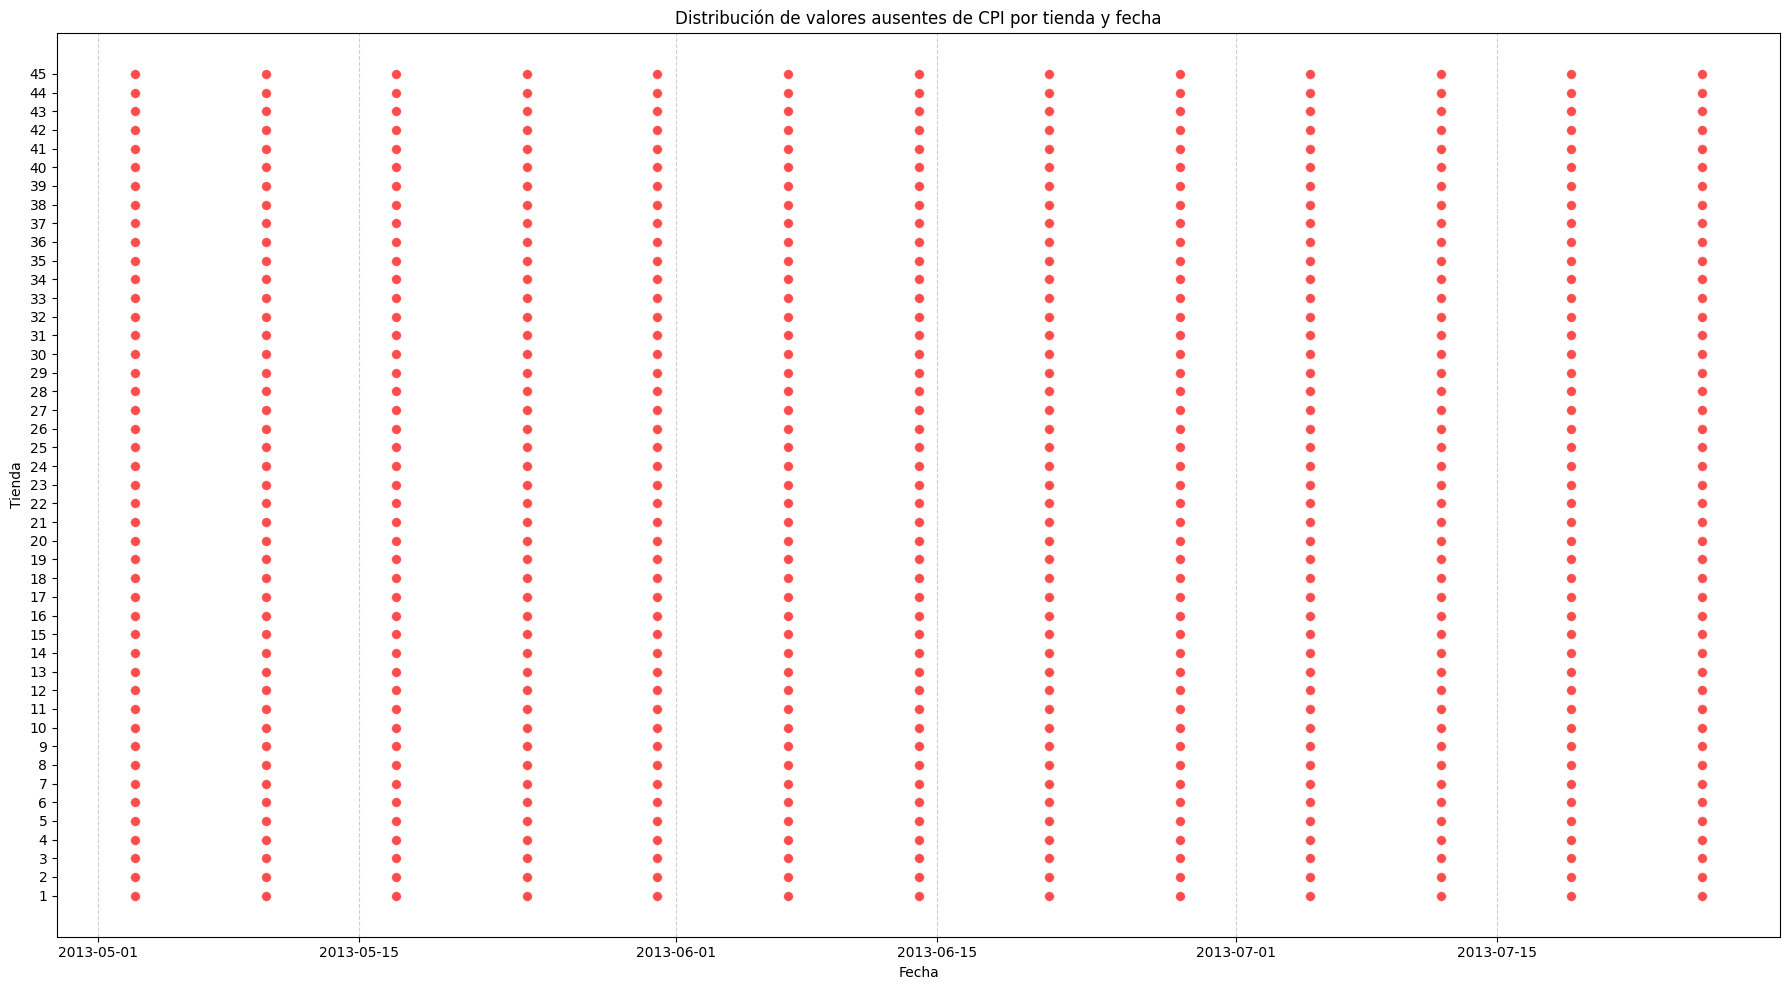

Total de valores ausentes en CPI: 585


In [17]:
# Seleccionamos únicamente los registros donde CPI tiene valores ausentes
missing_cpi = features[features['CPI'].isna()]

# Representamos en qué tiendas y fechas aparecen los valores ausentes
plt.figure(figsize=(18, 10))

sns.scatterplot(
    data=missing_cpi,
    x='Date',
    y='Store',
    s=50,
    color='red',
    alpha=0.7
)

plt.yticks(sorted(features['Store'].unique()))
plt.title('Distribución de valores ausentes de CPI por tienda y fecha')
plt.xlabel('Fecha')
plt.ylabel('Tienda')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Total de valores ausentes en CPI: {features['CPI'].isna().sum()}")

In [18]:
# Identificamos las fechas en las que ninguna tienda dispone de CPI
dates_all_cpi_missing = (
    features.groupby('Date')['CPI']
    .count() # Contamos los valores no nulos
    .loc[lambda count: count == 0] # Nos quedamos con las fechas con todas las tiendas con missing values
    .index # Nos quedamos solo con las fechas
)

print(
    f"Hay {len(dates_all_cpi_missing)} fechas donde el CPI "
    f"está ausente para las {features['Store'].nunique()} tiendas:"
)

print(dates_all_cpi_missing)

Hay 13 fechas donde el CPI está ausente para las 45 tiendas:
DatetimeIndex(['2013-05-03', '2013-05-10', '2013-05-17', '2013-05-24',
               '2013-05-31', '2013-06-07', '2013-06-14', '2013-06-21',
               '2013-06-28', '2013-07-05', '2013-07-12', '2013-07-19',
               '2013-07-26'],
              dtype='datetime64[ns]', name='Date', freq=None)


No disponemos de `CPI` para las 45 tiendas durante las últimas 13 semanas del conjunto de test. Esto limita su uso como variable explicativa si no conocemos su valor en el momento de predecir.

> En un primer momento se planteó la posibilidad de recuperar esta información a partir de registros externos del IPC, si se pudiera identificar la zona de cada tienda. Sin embargo, al investigar cómo hacerlo se vió que era muy complicado realizarlo sin asumir muchos supuestos. La principal limitación ha sido el no conocer la ubicación de las tiendas, ya que no sabemos a qué estado pertenecen, y por consiguiente cuál es su IPC.

> Al final no rellenamos estos valores con una fuente externa.

**Unemployment**

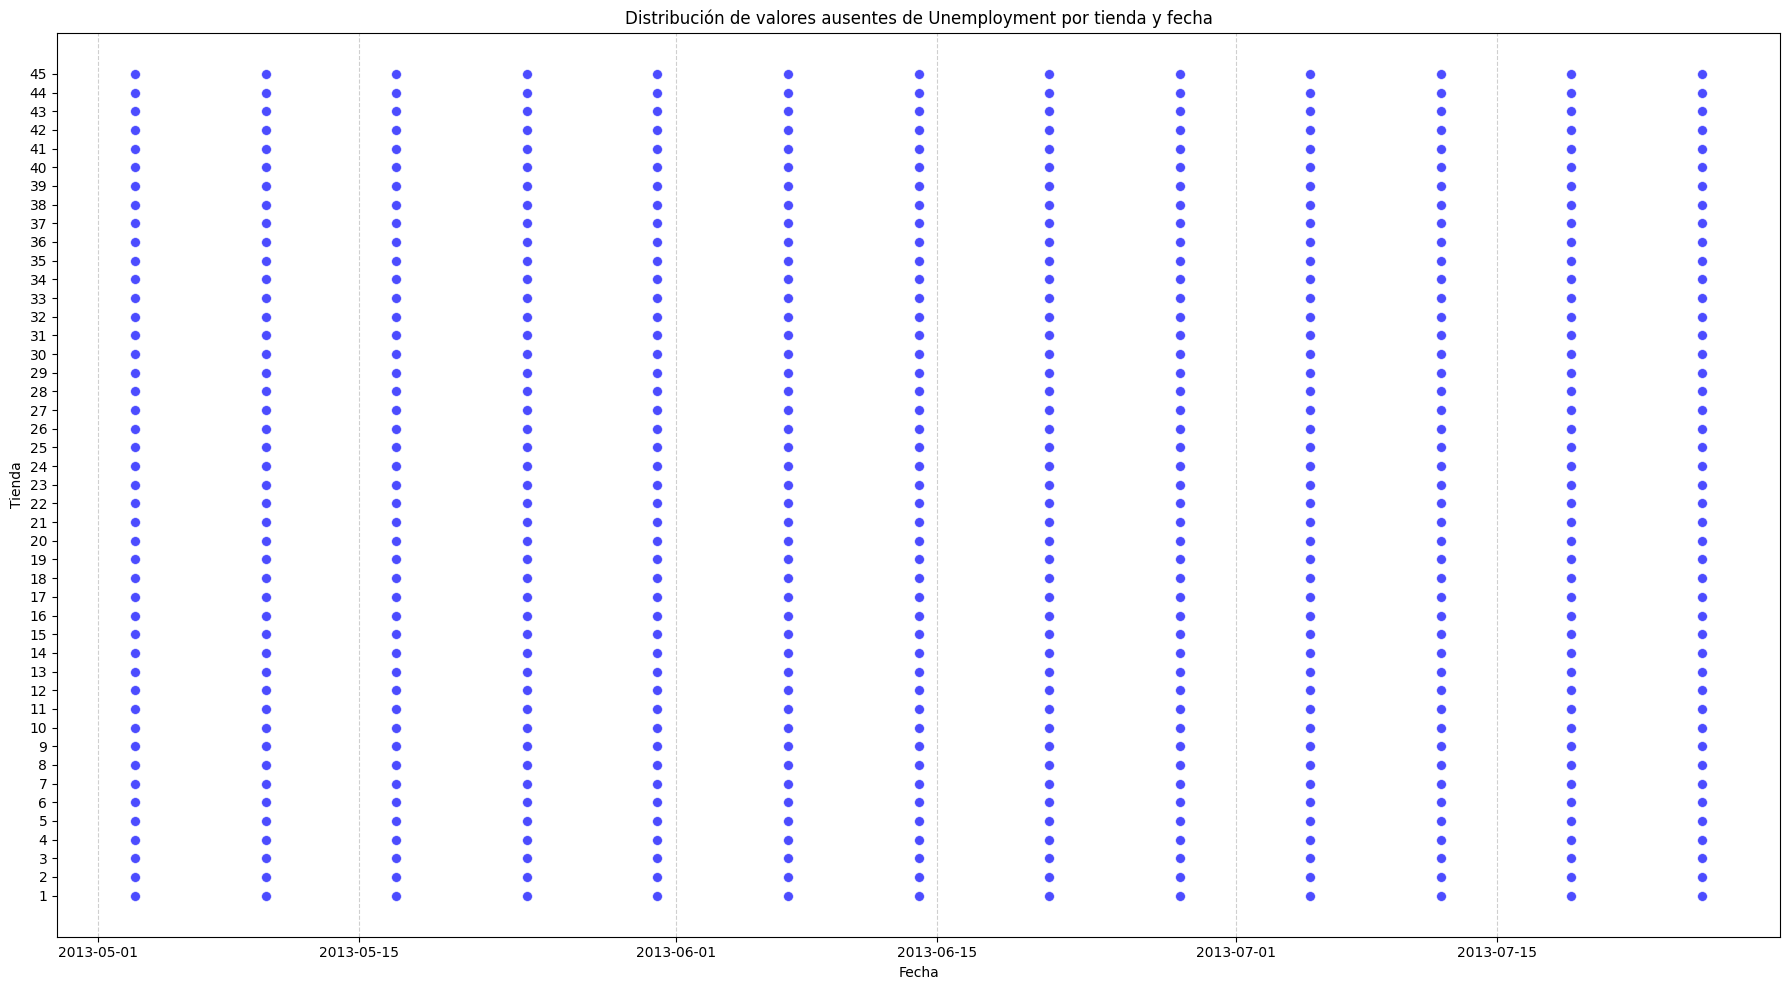

Total de valores ausentes en Unemployment: 585


In [19]:
# Seleccionamos únicamente los registros donde Unemployment tiene valores ausentes
missing_unemployment = features[features['Unemployment'].isna()]

# Representamos en qué tiendas y fechas aparecen los valores ausentes
plt.figure(figsize=(18, 10))

sns.scatterplot(
    data=missing_unemployment,
    x='Date',
    y='Store',
    s=50,
    color='blue',
    alpha=0.7
)

plt.yticks(sorted(features['Store'].unique()))
plt.title('Distribución de valores ausentes de Unemployment por tienda y fecha')
plt.xlabel('Fecha')
plt.ylabel('Tienda')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(
    f"Total de valores ausentes en Unemployment: "
    f"{features['Unemployment'].isna().sum()}"
)

En `Unemployment` aparece el mismo problema de disponibilidad. Vamos a comprobar si las fechas sin información coinciden con las de `CPI`; tampoco se rellenaron estos valores con una fuente externa en este notebook.

#### Comprobación conjunta de las ausencias

In [20]:
# 1. Cantidad y porcentaje de NaN para CPI y Unemployment
missing_cpi_count = features['CPI'].isna().sum()
missing_cpi_percentage = (missing_cpi_count / len(features)) * 100

missing_unemployment_count = features['Unemployment'].isna().sum()
missing_unemployment_percentage = (missing_unemployment_count / len(features)) * 100

print(f"CPI: {missing_cpi_count} valores ausentes ({missing_cpi_percentage:.2f}%)")
print(f"Unemployment: {missing_unemployment_count} valores ausentes ({missing_unemployment_percentage:.2f}%)")

CPI: 585 valores ausentes (7.14%)
Unemployment: 585 valores ausentes (7.14%)


Los gráficos anteriores sitúan las ausencias por tienda y fecha. La siguiente comprobación permite ver si ambas variables dejan de estar disponibles durante las mismas semanas.

In [21]:
# 2. Identificar fechas donde CPI y Unemployment son ausentes para todas las tiendas
# Las fechas donde todas las tiendas tienen CPI ausente ya se calcularon en `dates_all_cpi_missing`
# Ahora, para Unemployment:
dates_all_unemployment_missing = (
    features.groupby('Date')['Unemployment']
    .count()
    .loc[lambda count: count == 0]
    .index
)

print(f"Fechas donde CPI está ausente para todas las tiendas ({features['Store'].nunique()}):")
display(dates_all_cpi_missing.to_frame(name='Date'))

print(f"Fechas donde Unemployment está ausente para todas las tiendas ({features['Store'].nunique()}):")
display(dates_all_unemployment_missing.to_frame(name='Date'))

# Confirmamos que las fechas sin datos de CPI y Unemployment son las mismas.
common_missing_dates = dates_all_cpi_missing.intersection(dates_all_unemployment_missing)
print(f"Fechas comunes sin CPI ni Unemployment para todas las tiendas: {len(common_missing_dates)}")

Fechas donde CPI está ausente para todas las tiendas (45):


,Date
Date,
2013-05-03,2013-05-03
2013-05-10,2013-05-10
2013-05-17,2013-05-17
2013-05-24,2013-05-24
2013-05-31,2013-05-31
2013-06-07,2013-06-07
2013-06-14,2013-06-14
2013-06-21,2013-06-21
2013-06-28,2013-06-28


Fechas donde Unemployment está ausente para todas las tiendas (45):


,Date
Date,
2013-05-03,2013-05-03
2013-05-10,2013-05-10
2013-05-17,2013-05-17
2013-05-24,2013-05-24
2013-05-31,2013-05-31
2013-06-07,2013-06-07
2013-06-14,2013-06-14
2013-06-21,2013-06-21
2013-06-28,2013-06-28


Fechas comunes sin CPI ni Unemployment para todas las tiendas: 13


A continuación representamos los valores observados de `CPI` y `Unemployment` para contextualizar sus cambios a lo largo del tiempo y el tramo final sin información.

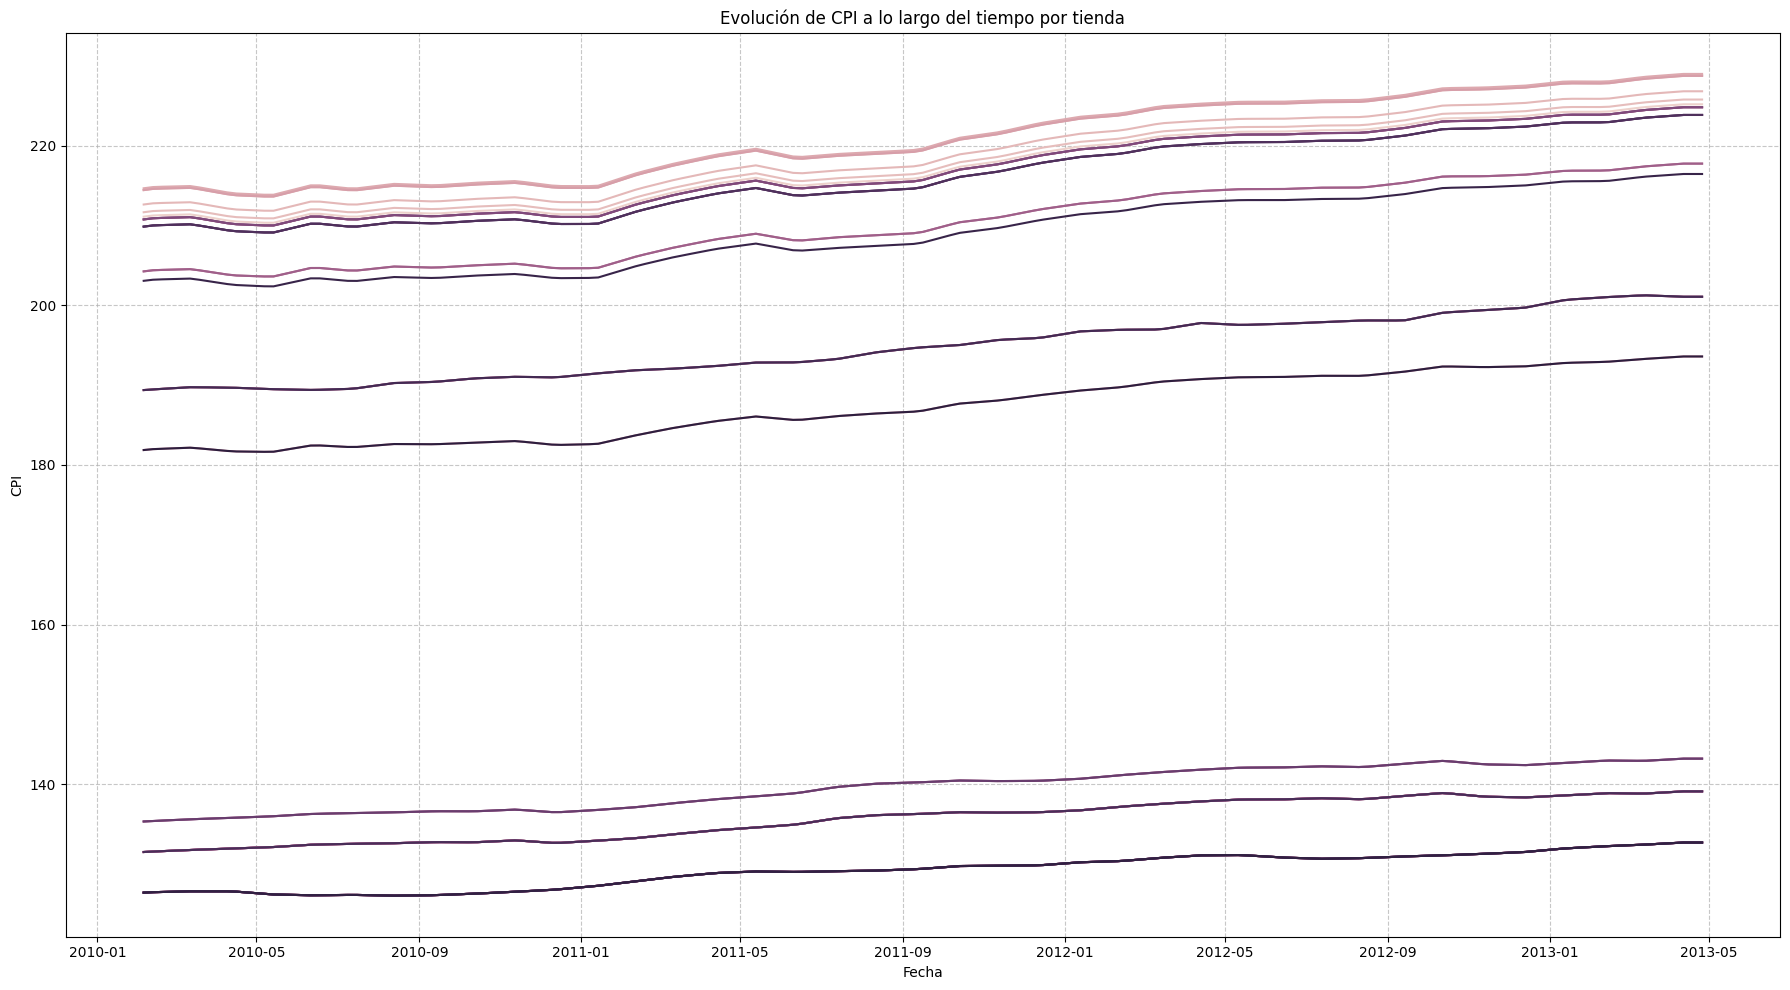

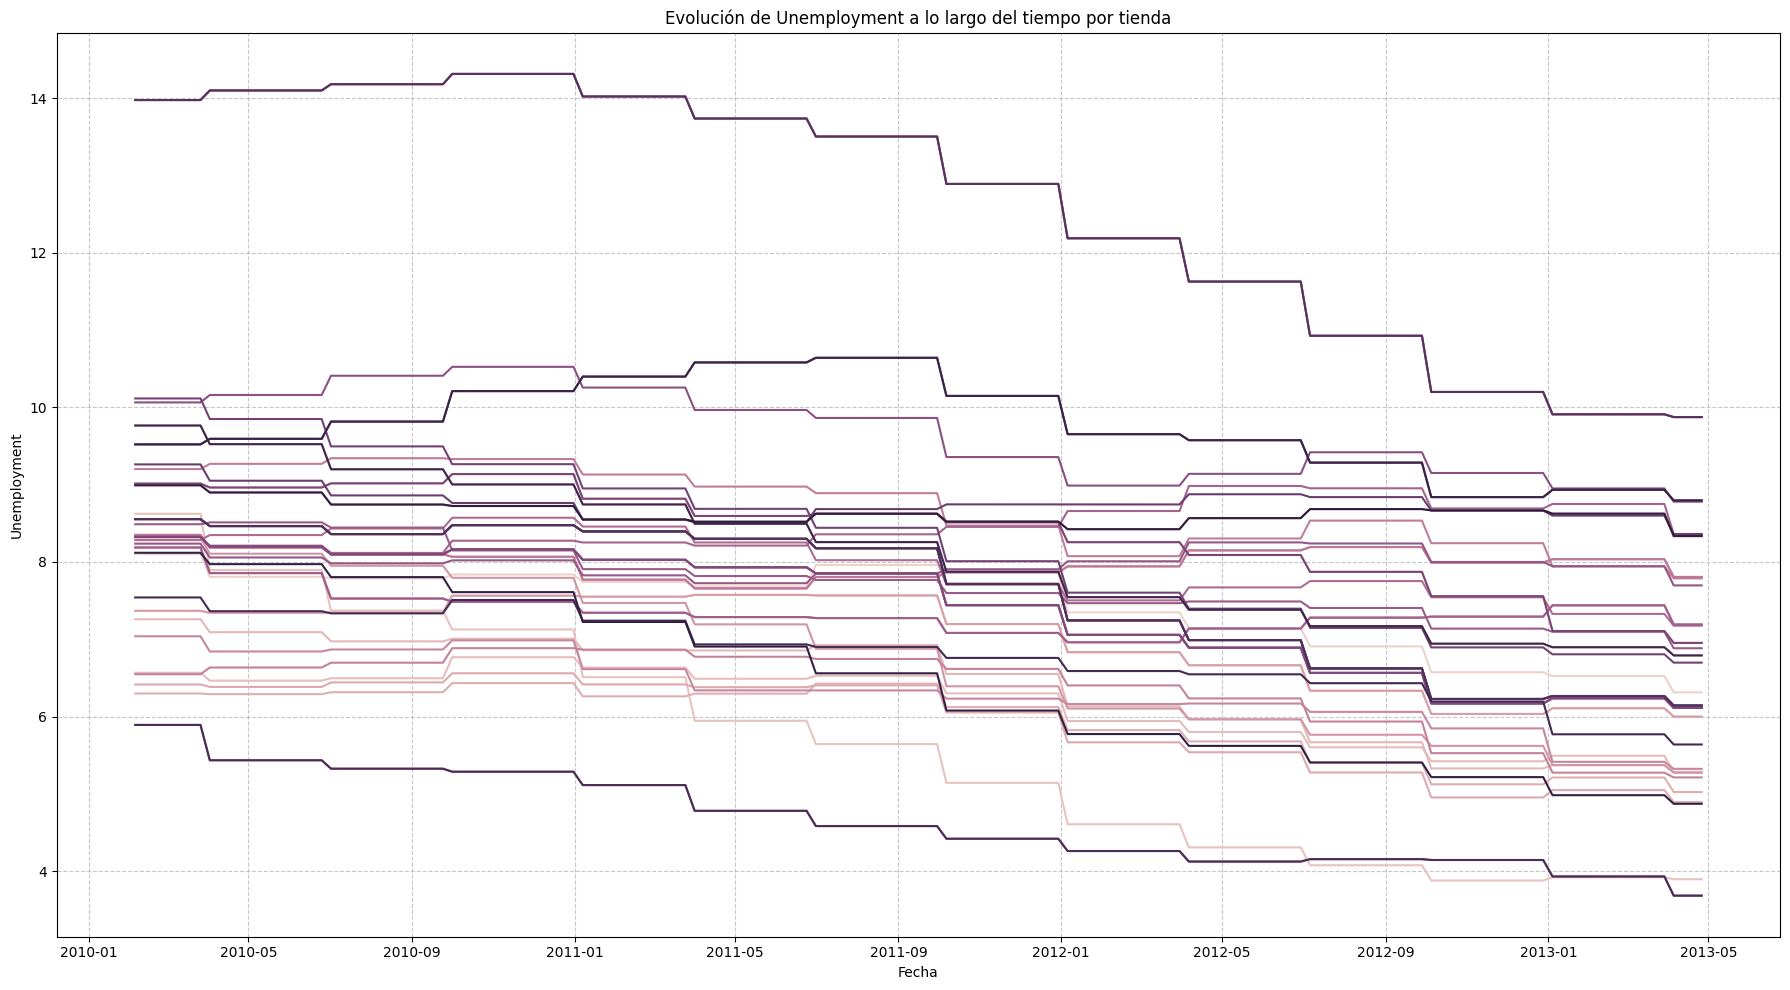

In [22]:
# Visualizamos la evolución temporal de las variables económicas por tienda
for variable in ['CPI', 'Unemployment']:

    plt.figure(figsize=(18, 10))

    sns.lineplot(
        data=features,
        x='Date',
        y=variable,
        hue='Store',
        legend=False
    )

    plt.title(f'Evolución de {variable} a lo largo del tiempo por tienda')
    plt.xlabel('Fecha')
    plt.ylabel(variable)
    plt.grid(linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

**Decisión de preparación**

Conservaremos `CPI` y `Unemployment` en el dataframe, incluidos sus valores ausentes. Así mantenemos la información original para la exploración y los primeros modelos. Su disponibilidad deberá tenerse en cuenta al elegir las variables predictivas; en este notebook no se estiman sus valores futuros.

## 4. Integración de los `features` y `Store`

Incorporamos las variables de `features_processed` mediante `Store`, `Date` e `IsHoliday`, y las características de `stores` mediante `Store`. Las uniones por la izquierda mantienen las observaciones de ventas de entrenamiento y las observaciones que deben predecirse en test. Al final comprobaremos las dimensiones, las claves y los valores ausentes de las tablas resultantes.

In [23]:
# =============================================================================
# GESTIÓN DE LOS DATASETS PROCESADOS
# =============================================================================
import hashlib
import json

PROCESSED_DIR = Path('/content/drive/MyDrive/TFM/data/processed')
PROCESSED_TRAIN = PROCESSED_DIR / 'train_processed.parquet'
PROCESSED_TEST = PROCESSED_DIR / 'test_processed.parquet'
PROCESSED_METADATA = PROCESSED_DIR / 'processed_source_signature.json'
# Incrementar solo si cambia la lógica de integración o preprocesamiento.
EDA_PREP_VERSION = 'eda-merge-markdown-v1'


def huella_tablas(tablas, version):
    """Firma del contenido de las fuentes, no solo de los nombres o fechas."""
    digest = hashlib.sha256(version.encode('utf-8'))
    for nombre, frame in tablas:
        digest.update(nombre.encode('utf-8'))
        digest.update(str(frame.shape).encode('utf-8'))
        digest.update('|'.join(map(str, frame.columns)).encode('utf-8'))
        digest.update('|'.join(map(str, frame.dtypes)).encode('utf-8'))
        valores = pd.util.hash_pandas_object(frame, index=False).to_numpy()
        digest.update(valores.tobytes())
    return digest.hexdigest()


def gestionar_procesados(train_nuevo, test_nuevo, firma_fuentes):
    """Trabajar con los datasets guardados, salvo regeneración necesaria."""
    archivos = [PROCESSED_TRAIN, PROCESSED_TEST]
    existen = all(p.exists() for p in archivos)
    razon = None

    if TRAIN:
        razon = 'TRAIN=True'
    elif not existen:
        razon = 'faltan datasets procesados'
    elif PROCESSED_METADATA.exists():
        try:
            metadata = json.loads(PROCESSED_METADATA.read_text(encoding='utf-8'))
            if metadata.get('source_signature') != firma_fuentes:
                razon = 'han cambiado las fuentes o el preprocesamiento'
        except (ValueError, OSError):
            razon = 'metadatos ilegibles'
    else:
        print('⚠ Dataset procesado antiguo sin firma: se conserva el archivo de Drive. '
              'No se puede verificar su correspondencia con el origen. '
              'Usa TRAIN=True para reconstruirlo y registrar su procedencia.')

    if razon is None:
        try:
            train_guardado = pd.read_parquet(PROCESSED_TRAIN)
            test_guardado = pd.read_parquet(PROCESSED_TEST)
            claves = {'Store', 'Dept', 'Date'}
            if (not claves.issubset(train_guardado.columns)
                    or not claves.issubset(test_guardado.columns)
                    or 'Weekly_Sales' not in train_guardado.columns
                    or 'Weekly_Sales' in test_guardado.columns):
                raise ValueError('esquema de columnas incompatible')
            print('✓ Se utilizan los datasets procesados guardados en Drive.')
            return train_guardado, test_guardado
        except (OSError, ValueError, KeyError) as exc:
            razon = f'no se pueden cargar los archivos: {exc}'

    print(f'↻ Reconstruyendo datasets procesados ({razon}).')
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    train_nuevo.to_parquet(PROCESSED_TRAIN, index=False)
    test_nuevo.to_parquet(PROCESSED_TEST, index=False)
    PROCESSED_METADATA.write_text(
        json.dumps({'source_signature': firma_fuentes,
                    'preprocessing_version': EDA_PREP_VERSION}, indent=2),
        encoding='utf-8'
    )
    print('✓ Datasets guardados/sobrescritos en Drive.')
    return train_nuevo, test_nuevo


In [24]:
# Añadimos al train las variables temporales, económicas y promocionales
train_merged = train.merge(
    features_processed,
    on=['Store', 'Date', 'IsHoliday'],
    how='left'
)

# Añadimos las características propias de cada tienda
train_merged = train_merged.merge(
    stores,
    on='Store',
    how='left'
)

# Añadimos al test las variables temporales, económicas y promocionales
test_merged = test.merge(
    features_processed,
    on=['Store', 'Date', 'IsHoliday'],
    how='left'
)

# Añadimos las características propias de cada tienda
test_merged = test_merged.merge(
    stores,
    on='Store',
    how='left'
)

display(train_merged.head())
display(test_merged.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,MarkDown5,CPI,Unemployment,MarkDown1_isna,MarkDown2_isna,MarkDown3_isna,MarkDown4_isna,MarkDown5_isna,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,0.0,211.096358,8.106,True,True,True,True,True,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,0.0,211.242170,8.106,True,True,True,True,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,0.0,211.289143,8.106,True,True,True,True,True,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,0.0,211.319643,8.106,True,True,True,True,True,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,0.0,211.350143,8.106,True,True,True,True,True,A,151315


,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,MarkDown1_isna,MarkDown2_isna,MarkDown3_isna,MarkDown4_isna,MarkDown5_isna,Type,Size
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,False,False,False,False,False,A,151315
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,False,False,False,False,False,A,151315
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,False,False,False,False,False,A,151315
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,False,False,False,False,False,A,151315
4,1,1,2012-11-30,False,52.34,3.207,2460.03,0.00,3838.35,150.57,6966.34,223.610984,6.573,False,True,False,False,False,A,151315


In [25]:
# =============================================================================
# SELECCIÓN DEL DATASET PROCESADO QUE USA EL RESTO DEL EDA
# =============================================================================
# Firma de las cuatro fuentes originales; las modificaciones externas a los
# parquet procesados se respetan si las fuentes originales no han cambiado.
firma_fuentes = huella_tablas(
    [('train', train), ('test', test), ('features', features), ('stores', stores)],
    EDA_PREP_VERSION
)
train_merged, test_merged = gestionar_procesados(
    train_merged, test_merged, firma_fuentes
)
print('Train utilizado:', train_merged.shape)
print('Test utilizado: ', test_merged.shape)


↻ Reconstruyendo datasets procesados (TRAIN=True).
✓ Datasets guardados/sobrescritos en Drive.
Train utilizado: (421570, 21)
Test utilizado:  (115064, 20)


## 5. Exploración de las ventas

Con las tablas integradas y las promociones preparadas, vamos a estudiar `Weekly_Sales`. `CPI` y `Unemployment` siguen teniendo valores ausentes en el tramo final de test.

Primero veremos la distribución de las ventas por tienda, departamento y semana; después, su evolución agregada y las diferencias entre tipos de tienda y departamentos. También revisaremos las ventas negativas y los valores extremos, sin eliminarlos.

In [26]:
# Estamos sumando todos los departamentos de todas las tiendas para cada fecha.
weekly_sales = train_merged.groupby('Date')['Weekly_Sales'].sum()
# Con esto sabemos las ventas totales por fecha
# Mínimo, máximo, media, mediana y percentiles de Weekly_Sales
print("\nEstadísticas descriptivas de Weekly_Sales:")
display(train_merged['Weekly_Sales'].describe(percentiles=[.01,0.25,0.75, .99]))


Estadísticas descriptivas de Weekly_Sales:


,Weekly_Sales
count,421570.000000
mean,15981.258123
std,22711.183519
min,-4988.940000
1%,5.000000
25%,2079.650000
50%,7612.030000
75%,20205.852500
99%,106479.586000
max,693099.360000


Las estadísticas descriptivas de `Weekly_Sales` permiten identificar varias características relevantes de la distribución de las ventas:

1. **Existen observaciones con ventas negativas**, alcanzándose un valor mínimo de -4.988,94. Estos registros presentan un comportamiento diferente al esperado para una variable de ventas, por lo que será necesario analizar posteriormente su frecuencia y distribución para determinar su relevancia dentro del conjunto de datos.

2. **La mayor parte de las observaciones presenta valores considerablemente más moderados.** El 50 % central de las ventas se encuentra aproximadamente entre 2.080 y 20.206, correspondientes a los percentiles 25 y 75, respectivamente. La mediana, situada en 7.612, es además notablemente inferior a la media de 15.981.

3. **La distribución presenta una fuerte asimetría hacia valores elevados.** La desviación típica (22.711) supera incluso a la media y el percentil 99 alcanza aproximadamente 106.480, muy por encima del percentil 75. Además, el máximo registrado asciende a 693.099. Todo ello indica la existencia de una cola derecha pronunciada formada por observaciones con ventas considerablemente superiores a los niveles habituales.

Por tanto, este primer análisis permite distinguir de forma exploratoria tres comportamientos que merecen ser estudiados por separado: **ventas negativas, ventas dentro del rango habitual y episodios de ventas excepcionalmente elevadas**. Los siguientes análisis permitirán estudiar la frecuencia, distribución y posible origen de estos comportamientos antes de valorar su tratamiento durante la fase de experimentación de los modelos.

In [27]:
# Variables complementarias

# Fechas festivas de todo el rango temporal
holiday_dates = (
    features_processed.loc[
        features_processed['IsHoliday'],
        'Date'
    ]
    .drop_duplicates()
    .sort_values()
)

# Calculamos las ventas semanales totales de cada tienda
store_weekly_sales = (# usamos el paréntesis para escribir en varias líneas
    train_merged
    .groupby(['Store', 'Type', 'Date'])['Weekly_Sales']
    .sum()
    .reset_index()
)
# Calculamos las ventas semanales medias por departamento entre tiendas y fechas
dept_weekly_sales = (
    train_merged
    .groupby('Dept')['Weekly_Sales']
    .mean() # Nos interesa la venta media, no el número de registros
    .reset_index()
)

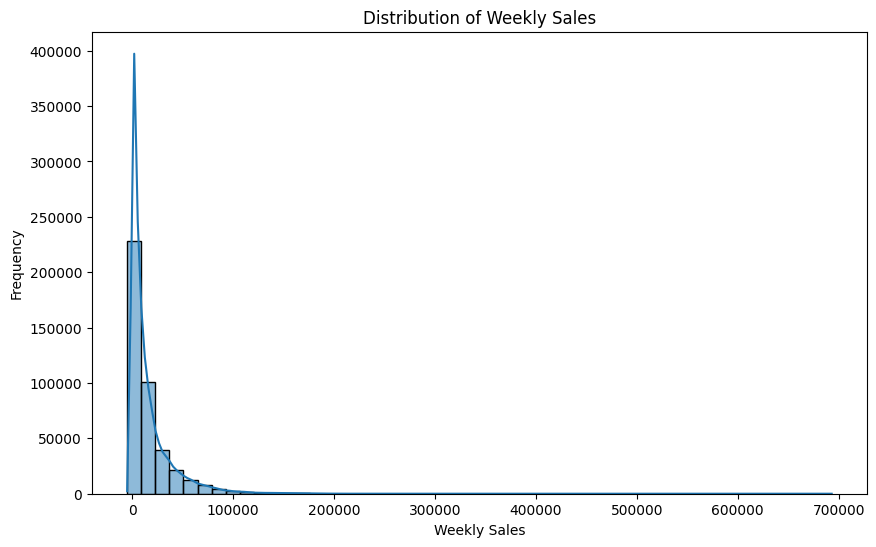

In [28]:
# 1. Distribución de las ventas semanales
# Vamos a agrupar todas ls observaciones por rangos de weekly sales

plt.figure(figsize=(10, 6))
sns.histplot(train_merged['Weekly_Sales'], bins=50, kde=True)
plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')
plt.show()



**Análisis Distribución de las ventas semanales**

La distribución de `Weekly_Sales` presenta una **fuerte asimetría positiva**. La gran mayoría de las observaciones se concentra en valores relativamente bajos de ventas, mientras que existe un número reducido de observaciones con ventas considerablemente superiores, generando una larga cola hacia la derecha.

Se observan incluso algunos valores de `Weekly_Sales` ligeramente negativos, que deberán analizarse posteriormente para determinar su origen y decidir su tratamiento.

Esta distribución indica que existen diferencias muy importantes entre las ventas de los distintos departamentos y tiendas. Además, la presencia de valores extremadamente elevados deberá tenerse en cuenta durante el entrenamiento de los modelos, ya que métricas sensibles a errores grandes, como el MSE, pueden verse especialmente afectadas por estas observaciones.


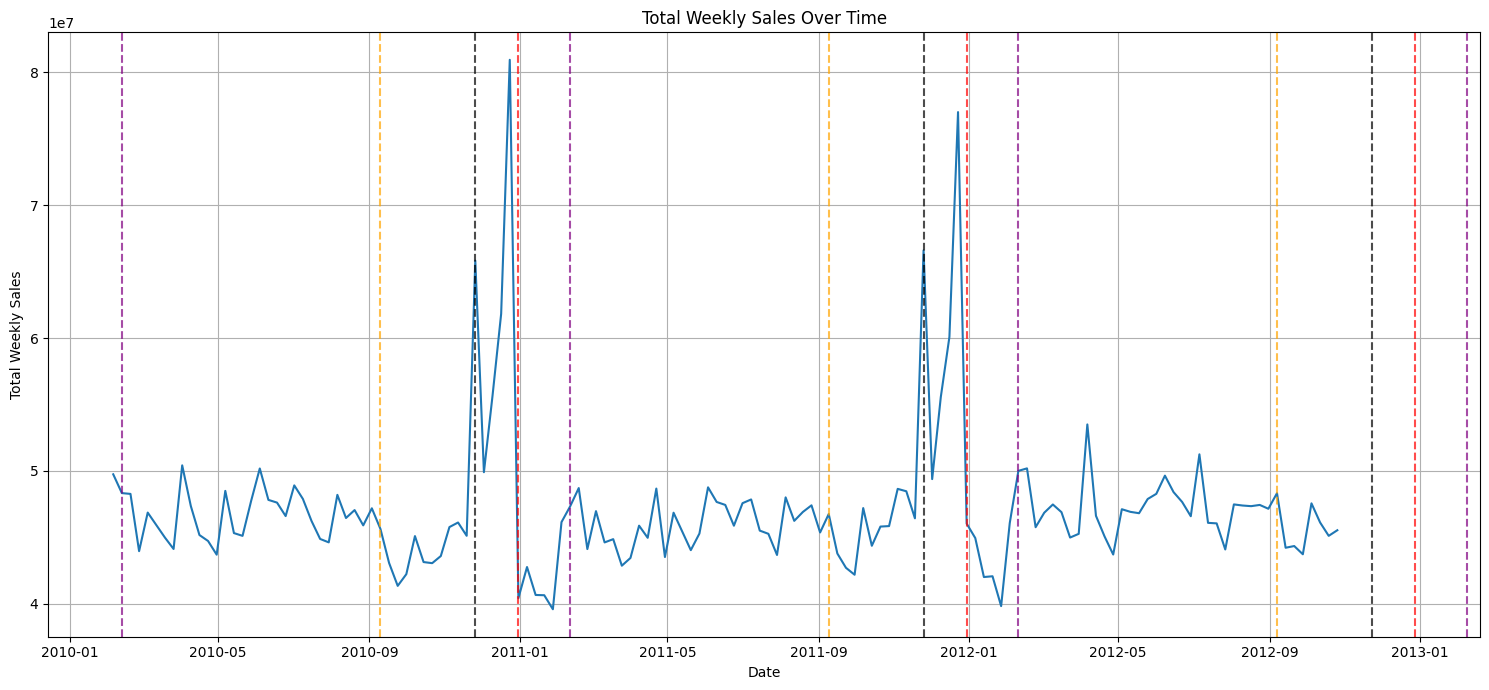

In [29]:
# 2. Evolución temporal de las ventas semanales totales
plt.figure(figsize=(15, 7))
sns.lineplot(
    x=weekly_sales.index, # El índice son las fechas
    y=weekly_sales.values # los values son las ventas totales
)

# Añadimos las líneas verticales de las festividades ya identificadas
for date in holiday_dates:
    label, color = holiday_info[date.month]
    plt.axvline(date, color=color, linestyle='--', alpha=0.7)

plt.title('Total Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')
plt.grid(True)
plt.tight_layout()
plt.show()

**Análisis de la evolución temporal de las ventas**

La evolución de las ventas semanales muestra un comportamiento relativamente estable durante gran parte del periodo analizado, aunque aparecen variaciones importantes y recurrentes hacia el final de cada año.

La comparación con las principales festividades permite observar que estas no afectan de la misma forma a las ventas. En las semanas correspondientes a la `Super Bowl` y `Labor Day` no se aprecian variaciones especialmente relevantes respecto a las semanas cercanas. `Thanksgiving`, por el contrario, coincide con uno de los mayores incrementos de ventas de toda la serie, patrón que se repite en los distintos años disponibles.

Durante el `periodo navideño` también se produce un incremento muy pronunciado de las ventas. Sin embargo, este no se concentra en la propia semana de Navidad, sino principalmente en las semanas inmediatamente anteriores. Tras este periodo se observa además una fuerte reducción de las ventas alrededor del comienzo del nuevo año.

Estos resultados evidencian la existencia de patrones estacionales relevantes y, especialmente, que el efecto de determinadas festividades no queda necesariamente limitado a la propia semana señalada como festiva. Este comportamiento deberá tenerse en cuenta posteriormente durante la construcción y experimentación con variables temporales para los modelos predictivos.


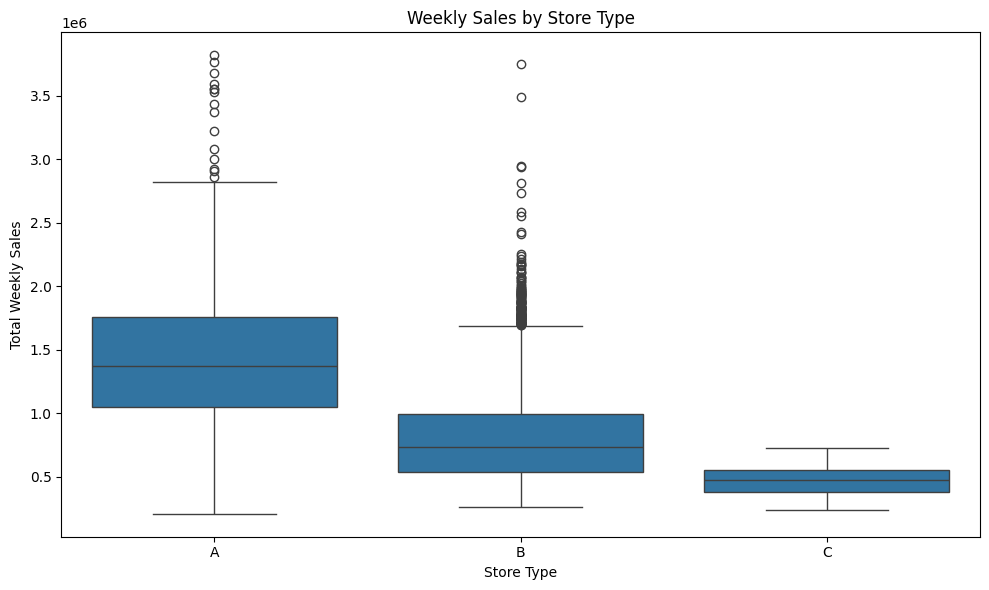

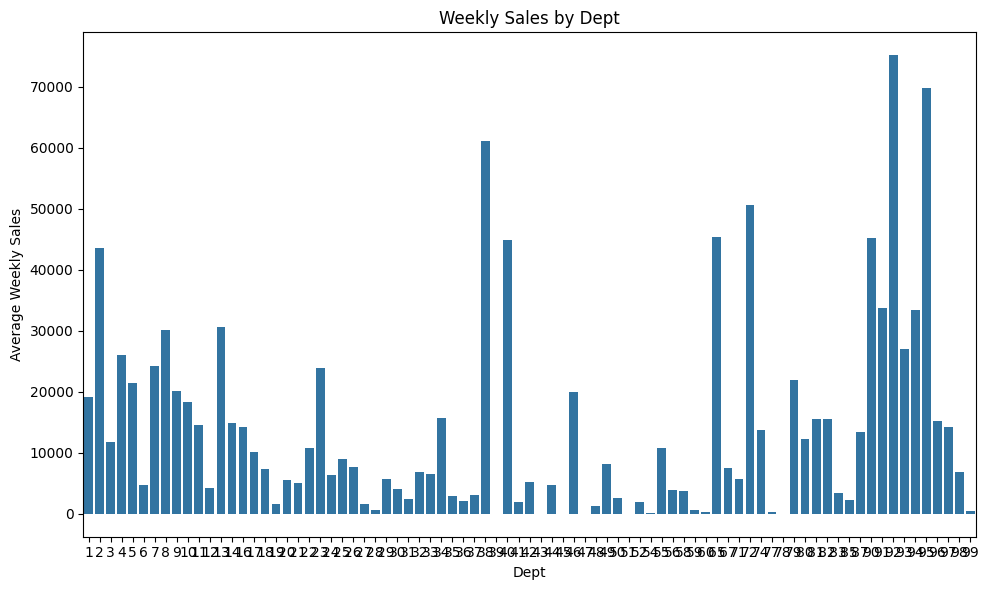

In [30]:
# Distribución de las ventas semanales según el tipo de tienda
plt.figure(figsize=(10, 6))

sns.boxplot(data=store_weekly_sales,x='Type',y='Weekly_Sales')
plt.title('Weekly Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Total Weekly Sales')
plt.tight_layout()
plt.show()

# Distribución de las ventas semanales según el departamento
plt.figure(figsize=(10, 6))

sns.barplot(data=dept_weekly_sales,x='Dept',y='Weekly_Sales')
plt.title('Weekly Sales by Dept')
plt.xlabel('Dept')
plt.ylabel('Average Weekly Sales')
plt.tight_layout()
plt.show()

**Ventas según el tipo de tienda y el departamento**

El diagrama de cajas compara las **ventas semanales totales de cada tienda**, obtenidas al sumar sus departamentos. Las tiendas de tipo `A` presentan, en general, mayores volúmenes de ventas, seguidas de las de tipo `B` y `C`. El tamaño y la composición de cada establecimiento pueden contribuir a estas diferencias.

El gráfico de departamentos utiliza otra agregación: muestra la **venta semanal media por departamento entre las tiendas y fechas disponibles**. Algunos departamentos tienen niveles habituales mucho mayores que otros. Por eso, una misma cifra de ventas puede ser normal en un departamento y excepcional en otro.

Estas diferencias justifican estudiar `Type` y `Dept` para contextualizar las ventas. Durante la exploración también se planteó excluir las tiendas `C` de una posible prueba centrada en ventas elevadas, pero esa idea no se aplica aquí: se conservan los tres tipos de tienda.

In [31]:
# Tamaño medio de cada tipo de tiendas
display(stores.groupby('Type')['Size'].mean())

,Size
Type,
A,177247.727273
B,101190.705882
C,40541.666667


Las tiendas `A` tienen el mayor tamaño medio, seguidas de las `B` y las `C`. Este orden coincide con el de sus ventas totales, aunque la comparación por sí sola no permite atribuir toda la diferencia al tamaño.

### 5.1. Ventas negativas y valores extremos

In [32]:
# 1. Número y porcentaje de valores negativos en Weekly_Sales
negative_sales_count = (train_merged['Weekly_Sales'] < 0).sum()
negative_sales_percentage = (negative_sales_count / len(train_merged)) * 100

print(f"Weekly_Sales negativas: {negative_sales_count} ({negative_sales_percentage:.2f}%)")

# 3. Tiendas/departamentos con Weekly_Sales negativas
negative_sales = train_merged[
    train_merged['Weekly_Sales'] < 0
]

print("\nDepartamentos con más ventas negativas:")
display(
    negative_sales['Dept']
    .value_counts()
    .head(10)
)

print("\nTiendas con más ventas negativas:")
display(negative_sales['Store'].value_counts().head(10))

# 4. Análisis de Outliers
Q1 = train_merged['Weekly_Sales'].quantile(0.25)
Q3 = train_merged['Weekly_Sales'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_merged[
    (train_merged['Weekly_Sales'] < lower_bound) |
    (train_merged['Weekly_Sales'] > upper_bound)
]

print(
    f"Outliers según IQR: {len(outliers)} "
    f"({len(outliers) / len(train_merged) * 100:.2f}%)"
)

Weekly_Sales negativas: 1285 (0.30%)

Departamentos con más ventas negativas:


,count
Dept,
47,254
18,180
54,146
19,87
94,77
80,68
49,67
59,44
72,34



Tiendas con más ventas negativas:


,count
Store,
35,124
18,52
10,50
17,49
15,45
42,44
22,41
31,39
20,38


Outliers según IQR: 35521 (8.43%)


#### Distribución por departamentos

In [33]:
# Comprobamos cómo se distribuyen las ventas negativas entre departamentos
negative_sales_by_dept = (
    negative_sales.groupby('Dept')
    .agg(
        Negative_Sales=('Weekly_Sales', 'count'),
        Min_Sale=('Weekly_Sales', 'min'),
        Mean_Negative_Sale=('Weekly_Sales', 'mean'),
        Stores=('Store', 'nunique')
    )
    .sort_values('Negative_Sales', ascending=False)
)

display(negative_sales_by_dept.head(15))

,Negative_Sales,Min_Sale,Mean_Negative_Sale,Stores
Dept,,,,
47,254,-3924.00,-209.401811,36
18,180,-175.54,-10.105833,37
54,146,-465.08,-33.080890,35
19,87,-69.56,-11.984598,16
94,77,-173.84,-8.412727,14
80,68,-590.04,-62.227647,12
49,67,-326.61,-21.731045,12
59,44,-55.46,-9.359545,12
72,34,-379.00,-89.634706,6


In [34]:
# Calculamos el número total de observaciones y de ventas negativas por departamento
sales_by_dept = train_merged.groupby('Dept').size().rename('Total_Sales')

negative_by_dept = negative_sales.groupby('Dept').size().rename('Negative_Sales')

# Combinamos ambos resultados y calculamos el porcentaje de ventas negativas
negative_sales_by_dept = pd.concat(
    [sales_by_dept, negative_by_dept],
    axis=1
).fillna(0)

negative_sales_by_dept['Negative_Percentage'] = (
    negative_sales_by_dept['Negative_Sales']
    / negative_sales_by_dept['Total_Sales']
    * 100
)

display(
    negative_sales_by_dept
    .sort_values('Negative_Percentage', ascending=False)
    .head(20)
)

,Total_Sales,Negative_Sales,Negative_Percentage
Dept,,,
47,646,254.0,39.318885
78,235,33.0,14.042553
77,150,16.0,10.666667
18,5029,180.0,3.579240
54,4767,146.0,3.062723
19,4119,87.0,2.112163
51,1394,25.0,1.793400
49,4482,67.0,1.494868
94,5685,77.0,1.354442


Para la mayoría de departamentos, las ventas negativas son excepcionales y podrían considerarse ruido o ajustes puntuales. En cambio, en los departamentos `47`, `77` y `78` su frecuencia es suficientemente alta como para considerarlas parte estructural de su comportamiento y analizarlas de forma específica antes de cualquier eliminación.

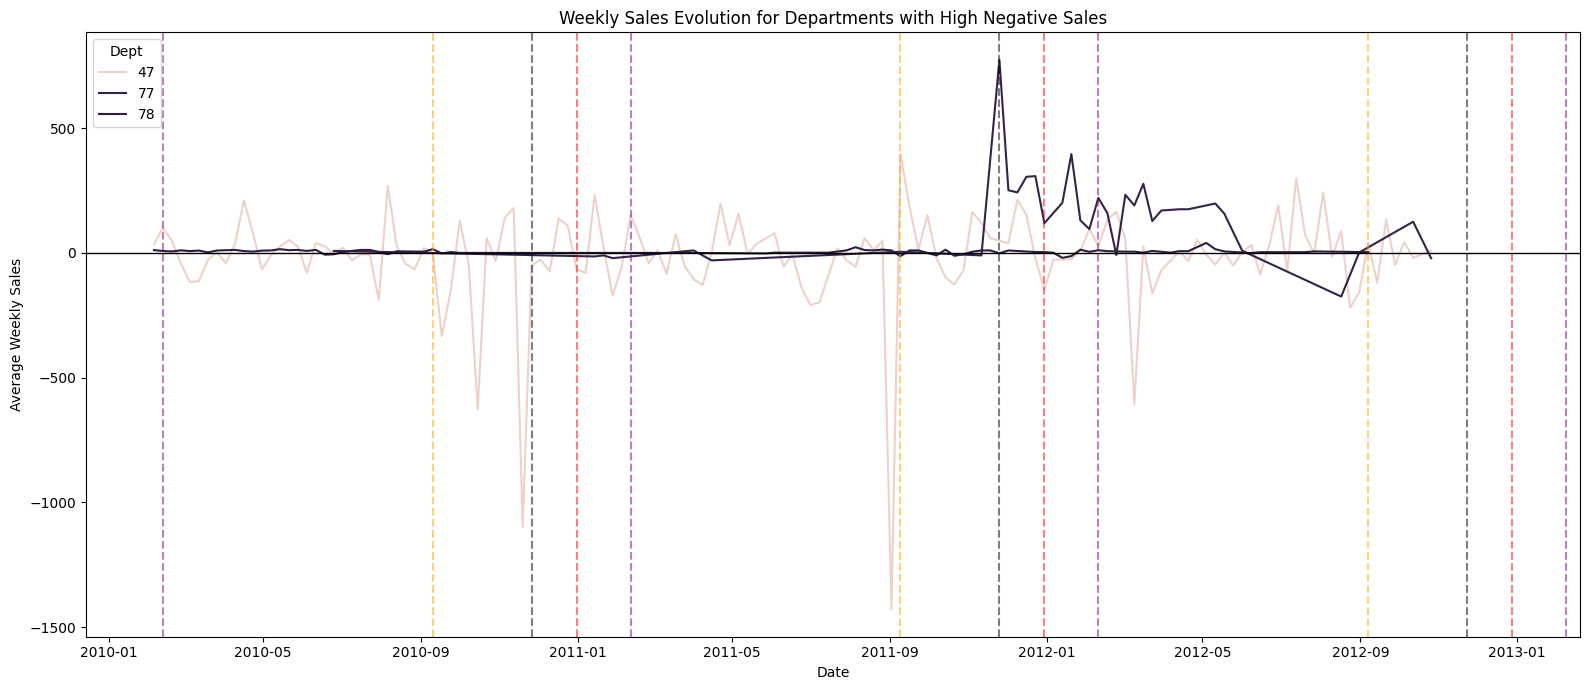

,Total_Observations,Mean_Sales,Median_Sales,Min_Sales,Max_Sales,Negative_Observations,Mean_Negative_Sale,Mean_Positive_Sale
Dept,,,,,,,,
47,646,-7.682554,17.985,-3924.0,1098.0,254,-209.401811,123.023291
77,150,328.961800,198.000,-175.0,1590.0,16,-34.210625,372.325672
78,235,7.296638,9.880,-24.0,60.0,33,-10.672727,10.232228


In [35]:
# Departamentos con una proporción especialmente alta de ventas negativas
selected_depts = [47, 77, 78]

# Evolución semanal media de cada departamento entre las tiendas
dept_sales_evolution = (
    train_merged[train_merged['Dept'].isin(selected_depts)]
    .groupby(['Dept', 'Date'])['Weekly_Sales']
    .mean()
    .reset_index()
)

plt.figure(figsize=(16, 7))

sns.lineplot(
    data=dept_sales_evolution,
    x='Date',
    y='Weekly_Sales',
    hue='Dept'
)

# Marcamos las semanas festivas utilizando las variables creadas anteriormente
for date in holiday_dates:
    label, color = holiday_info[date.month]
    plt.axvline(date, color=color, linestyle='--', alpha=0.5)

plt.axhline(0, color='black', linewidth=1)
plt.title('Weekly Sales Evolution for Departments with High Negative Sales')
plt.xlabel('Date')
plt.ylabel('Average Weekly Sales')
plt.tight_layout()
plt.show()


# Comparamos la magnitud de las ventas positivas y negativas
dept_sales_summary = (
    train_merged[train_merged['Dept'].isin(selected_depts)]
    .groupby('Dept')['Weekly_Sales']
    .agg(
        Total_Observations='count',
        Mean_Sales='mean',
        Median_Sales='median',
        Min_Sales='min',
        Max_Sales='max'
    )
)

dept_sales_summary['Negative_Observations'] = (
    train_merged[
        train_merged['Dept'].isin(selected_depts) &
        (train_merged['Weekly_Sales'] < 0)
    ]
    .groupby('Dept')['Weekly_Sales']
    .count()
)

dept_sales_summary['Mean_Negative_Sale'] = (
    train_merged[
        train_merged['Dept'].isin(selected_depts) &
        (train_merged['Weekly_Sales'] < 0)
    ]
    .groupby('Dept')['Weekly_Sales']
    .mean()
)

dept_sales_summary['Mean_Positive_Sale'] = (
    train_merged[
        train_merged['Dept'].isin(selected_depts) &
        (train_merged['Weekly_Sales'] >= 0)
    ]
    .groupby('Dept')['Weekly_Sales']
    .mean()
)

display(dept_sales_summary)

Se han identificado 1.285 observaciones con valores negativos de `Weekly_Sales`, que representan aproximadamente el 0,30 % del conjunto de datos. Aunque su incidencia global es reducida, estos registros no se distribuyen uniformemente entre los distintos departamentos.

Los departamentos 47, 77 y 78 presentan las mayores proporciones de ventas negativas, con aproximadamente un 39 %, 11 % y 14 % de sus observaciones, respectivamente. El departamento 47 resulta especialmente destacable, ya que las ventas negativas aparecen de forma recurrente y alcanzan magnitudes considerablemente superiores a las observadas en los otros departamentos analizados. En los departamentos 77 y 78, aunque la proporción de valores negativos también es elevada, estos presentan generalmente una magnitud menor.

El conjunto de datos no proporciona información suficiente para determinar el origen de estos valores. Una posible explicación sería la existencia de devoluciones, reembolsos o ajustes sobre las ventas registradas, aunque esta interpretación no puede confirmarse con la información disponible. Desde una perspectiva comercial, una elevada frecuencia de ventas netas negativas en determinadas categorías podría justificar un análisis específico de los productos correspondientes o de las políticas de venta y devolución asociadas.

Conservamos las ventas negativas, ya que no existe evidencia suficiente para considerarlas errores. La posibilidad de comparar modelos con y sin estas observaciones surgió durante la exploración, pero no se aplica ninguna exclusión en esta preparación de los datos.

#### Distribución por tiendas

In [36]:
# Calculamos el número y porcentaje de ventas negativas por tienda
negative_sales_by_store = (
    negative_sales.groupby('Store')
    .size()
    .rename('Negative_Sales')
    .to_frame()
)

negative_sales_by_store['Total_Sales'] = (
    train_merged.groupby('Store').size()
)

negative_sales_by_store['Negative_Percentage'] = (
    negative_sales_by_store['Negative_Sales']
    / negative_sales_by_store['Total_Sales']
    * 100
)

# Mostramos las tiendas con mayor proporción de ventas negativas
display(
    negative_sales_by_store
    .sort_values('Negative_Percentage', ascending=False)
)

,Negative_Sales,Total_Sales,Negative_Percentage
Store,,,
35,124,9528,1.301427
42,44,6953,0.632820
18,52,9859,0.527437
17,49,9864,0.496756
10,50,10315,0.484731
15,45,9901,0.454500
22,41,9688,0.423204
16,38,9443,0.402414
36,25,6222,0.401800


Por tienda, las ventas negativas representan porcentajes reducidos. No aparece una concentración comparable a la observada en algunos departamentos, aunque este resumen no permite determinar el origen de los registros negativos.

## 6. Ventas durante las campañas festivas

La evolución agregada muestra aumentos alrededor de Thanksgiving y de las semanas previas a Navidad. Vamos a descomponer estas diferencias por departamento y por tienda para entender dónde se concentran.

Las comparaciones son descriptivas: contrastan las ventas medias de distintos periodos, sin aislar un efecto causal de la festividad.

### 6.1. Comparación por departamentos

#### Thanksgiving

In [37]:
thanksgiving_dates = [
    date for date in holiday_dates
    if date.month == 11
]

# Calculamos las ventas medias de cada departamento
# distinguiendo entre Thanksgiving y el resto de semanas
dept_thanksgiving = (
    train_merged
    .assign(
        Thanksgiving=train_merged['Date'].isin(thanksgiving_dates)
    )
    .groupby(['Dept', 'Thanksgiving'])['Weekly_Sales']
    .mean()
    .unstack()
    .rename(columns={
        False: 'Normal_Sales',
        True: 'Thanksgiving_Sales'
    })
)

dept_thanksgiving['Normal_Observations'] = (
    train_merged[
        ~train_merged['Date'].isin(thanksgiving_dates)
    ]
    .groupby('Dept')
    .size()
)

# Número de observaciones de cada departamento durante Thanksgiving
dept_thanksgiving['Thanksgiving_Observations'] = (
    train_merged[
        train_merged['Date'].isin(thanksgiving_dates)
    ]
    .groupby('Dept').size()
).astype(int)

# Calculamos cuánto aumentan o disminuyen las ventas respecto al nivel habitual
dept_thanksgiving['Change_%'] = (
    (dept_thanksgiving['Thanksgiving_Sales'] - dept_thanksgiving['Normal_Sales'])
    / dept_thanksgiving['Normal_Sales']
    * 100
)

# Calculamos también la variación absoluta de las ventas
dept_thanksgiving['Change_Absolute'] = (
    dept_thanksgiving['Thanksgiving_Sales']
    - dept_thanksgiving['Normal_Sales']
)

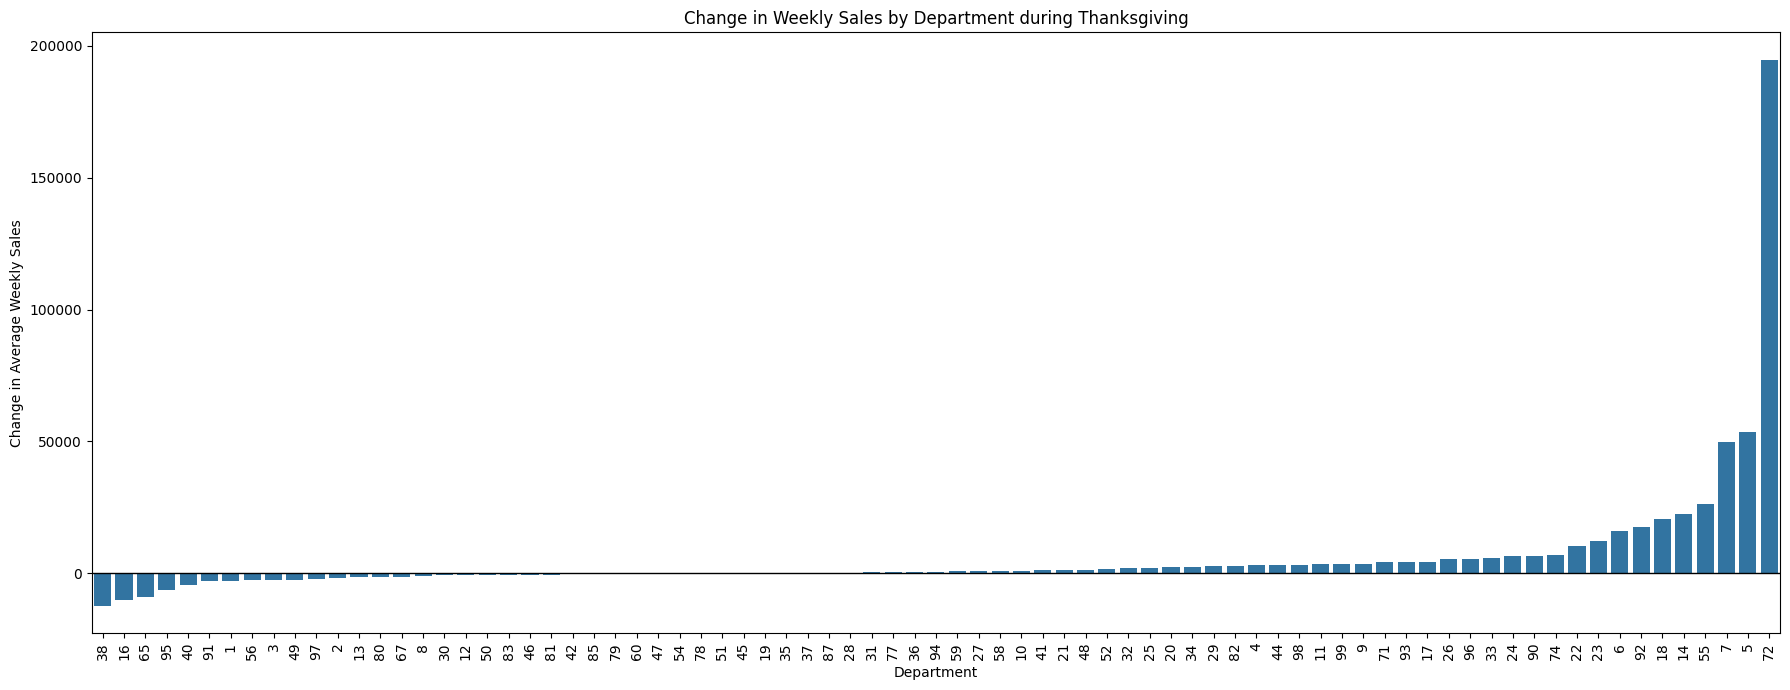

In [38]:
# Ordenamos los departamentos según el cambio absoluto de ventas en Thanksgiving
thanksgiving_changes = (
    dept_thanksgiving
    .dropna(subset=['Change_Absolute'])
    .sort_values('Change_Absolute')
    .reset_index()
)

plt.figure(figsize=(18, 7))

sns.barplot(
    data=thanksgiving_changes,
    x='Dept',
    y='Change_Absolute',
    order=thanksgiving_changes['Dept']
)

# Línea de referencia: ausencia de cambio
plt.axhline(0, color='black', linewidth=1)

plt.title('Change in Weekly Sales by Department during Thanksgiving')
plt.xlabel('Department')
plt.ylabel('Change in Average Weekly Sales')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [39]:
thanksgiving_ranked = (
  dept_thanksgiving.dropna(subset=['Change_Absolute'])
  .sort_values('Change_Absolute', ascending=False)
  )

print('Departamentos con mayor incremento de ventas:')
display(thanksgiving_ranked.head(10))

print('\nDepartamentos con mayor reducción de ventas:')
display(thanksgiving_ranked.tail(10).sort_values('Change_Absolute'))

Departamentos con mayor incremento de ventas:


Thanksgiving,Normal_Sales,Thanksgiving_Sales,Normal_Observations,Thanksgiving_Observations,Change_%,Change_Absolute
Dept,,,,,,
72,47827.848829,242627.592235,5961,85.0,407.293550,194799.743406
5,20614.310730,74191.033933,6258,89.0,259.900629,53576.723202
7,23465.215694,73230.768556,6345,90.0,212.082231,49765.552861
55,10350.035685,36653.313333,5518,78.0,254.137072,26303.277648
14,14558.414443,36905.853444,6345,90.0,153.501874,22347.439002
18,6969.339814,27510.219111,4939,90.0,294.732067,20540.879297
92,74961.322648,92374.996333,6345,90.0,23.230211,17413.673686
6,4516.190424,20641.205116,5900,86.0,357.049043,16125.014693
23,23765.768202,35876.973038,5695,79.0,50.960713,12111.204836



Departamentos con mayor reducción de ventas:


Thanksgiving,Normal_Sales,Thanksgiving_Sales,Normal_Observations,Thanksgiving_Observations,Change_%,Change_Absolute
Dept,,,,,,
38,61262.005136,49007.937000,6345,90.0,-20.002721,-12254.068136
16,14387.303667,4258.227778,6345,90.0,-70.402878,-10129.075890
65,45564.761135,36766.335000,141,2.0,-19.309716,-8798.426135
95,69915.021652,63437.223778,6345,90.0,-9.265245,-6477.797874
40,44964.294281,40417.498222,6345,90.0,-10.112015,-4546.796058
91,33730.560199,30681.125222,6345,90.0,-9.040570,-3049.434976
1,19251.610392,16525.651111,6345,90.0,-14.159643,-2725.959281
56,3869.230071,1385.943095,5788,84.0,-64.180391,-2483.286976
3,11827.938274,9379.795556,6345,90.0,-20.697967,-2448.142719


**Efecto de Thanksgiving según el departamento**

El análisis muestra que el incremento global de ventas observado durante Thanksgiving(**acción de gracias**) no se distribuye uniformemente entre los distintos departamentos. Por el contrario, se identifican comportamientos considerablemente diferentes.

Una gran parte de los departamentos presenta variaciones relativamente reducidas respecto a sus niveles habituales de venta, mientras que un grupo más reducido concentra incrementos muy elevados. El caso más destacado corresponde al departamento 72, cuyas ventas medias pasan de aproximadamente 47.828 a 242.628 durante Thanksgiving, lo que supone un incremento superior al 400 %. Los departamentos 5, 7, 55, 18 y 6 también presentan incrementos especialmente elevados.

La comparación entre variaciones absolutas y relativas permite además distinguir diferentes comportamientos. Algunos departamentos experimentan grandes incrementos porcentuales respecto a su nivel habitual, mientras que otros, al operar normalmente con mayores volúmenes de venta, pueden generar incrementos absolutos importantes incluso con variaciones porcentuales más moderadas.

Por otra parte, no todos los departamentos presentan mayores ventas durante Thanksgiving. Algunos presentan reducciones respecto a su comportamiento habitual. Destacan los departamentos 38 y 16, con reducciones medias superiores a 10.000, así como el departamento 56, cuyas ventas disminuyen aproximadamente un 64 %. Estos resultados sugieren que el efecto de Thanksgiving no consiste únicamente en un incremento generalizado de la demanda, sino que afecta de manera diferente a las distintas categorías de producto.

Los resultados deben interpretarse teniendo en cuenta también el número de observaciones disponibles. La mayoría de los principales departamentos analizados dispone de un número elevado de registros durante Thanksgiving, mientras que determinados casos, como el departamento 65, cuentan con muy pocas observaciones y no permiten extraer conclusiones igualmente robustas.

Desde el punto de vista predictivo, esta heterogeneidad señala la importancia de considerar conjuntamente el departamento y el calendario. La comparación no determina por sí sola cómo debe representarse esa relación en un modelo.

#### Campaña navideña
A diferencia de Thanksgiving, cuyo efecto se concentra principalmente en una semana concreta, el periodo navideño presenta un comportamiento más prolongado. Las ventas aumentan durante las semanas previas a Navidad y posteriormente muestran una caída notable durante la propia festividad y las primeras semanas de enero.

Por este motivo, para analizar el efecto prenavideño no resulta adecuado comparar estas semanas con todas las observaciones restantes, ya que el periodo inmediatamente posterior también presenta un comportamiento estacional anómalo y podría distorsionar el nivel de referencia.

En este caso se compararán las tres semanas anteriores a la fecha semanal marcada como Christmas en el conjunto de datos con aquellas semanas situadas fuera de la campaña navideña y del periodo inmediatamente posterior. De esta forma, la referencia representa mejor el comportamiento habitual de cada departamento.

En el código, la referencia excluye esas tres semanas y también la semana marcada como Christmas y las cuatro siguientes. Esta definición se mantiene después en la comparación por tiendas.

In [40]:
# Identificamos las fechas correspondientes a Navidad
christmas_dates = [
    date for date in holiday_dates
    if date.month == 12
]

# Identificamos las tres semanas anteriores a cada Navidad
pre_christmas_dates = []

for christmas_date in christmas_dates:
    pre_christmas_dates.extend([
        christmas_date - pd.Timedelta(weeks=1),
        christmas_date - pd.Timedelta(weeks=2),
        christmas_date - pd.Timedelta(weeks=3)
    ])

pre_christmas_dates = pd.to_datetime(pre_christmas_dates)

# Periodo que excluiremos de la referencia normal:
# semana de Navidad + primeras semanas de enero
post_christmas_dates = []

for christmas_date in christmas_dates:
    post_christmas_dates.extend([
        christmas_date,
        christmas_date + pd.Timedelta(weeks=1),
        christmas_date + pd.Timedelta(weeks=2),
        christmas_date + pd.Timedelta(weeks=3),
        christmas_date + pd.Timedelta(weeks=4)
    ])

post_christmas_dates = pd.to_datetime(post_christmas_dates)


# Máscaras para separar campaña prenavideña y semanas normales
pre_christmas_mask = train_merged['Date'].isin(pre_christmas_dates)

normal_mask = ~train_merged['Date'].isin(
    list(pre_christmas_dates) + list(post_christmas_dates)
)

In [41]:
# Ventas medias por departamento
normal_sales = (
    train_merged[normal_mask]
    .groupby('Dept')['Weekly_Sales']
    .mean()
)

pre_christmas_sales = (
    train_merged[pre_christmas_mask]
    .groupby('Dept')['Weekly_Sales']
    .mean()
)

dept_christmas = pd.concat(
    [normal_sales, pre_christmas_sales],
    axis=1
)

dept_christmas.columns = [
    'Normal_Sales',
    'Pre_Christmas_Sales'
]


# Número de observaciones
dept_christmas['Normal_Observations'] = (
    train_merged[normal_mask]
    .groupby('Dept')
    .size()
)

dept_christmas['Pre_Christmas_Observations'] = (
    train_merged[
        train_merged['Date'].isin(pre_christmas_dates)
    ]
    .groupby('Dept')
    .size()
)

# Cambio relativo y absoluto
dept_christmas['Change_%'] = (
    (dept_christmas['Pre_Christmas_Sales'] - dept_christmas['Normal_Sales'])
    / dept_christmas['Normal_Sales']
    * 100
)

dept_christmas['Change_Absolute'] = (
    dept_christmas['Pre_Christmas_Sales']
    - dept_christmas['Normal_Sales']
)

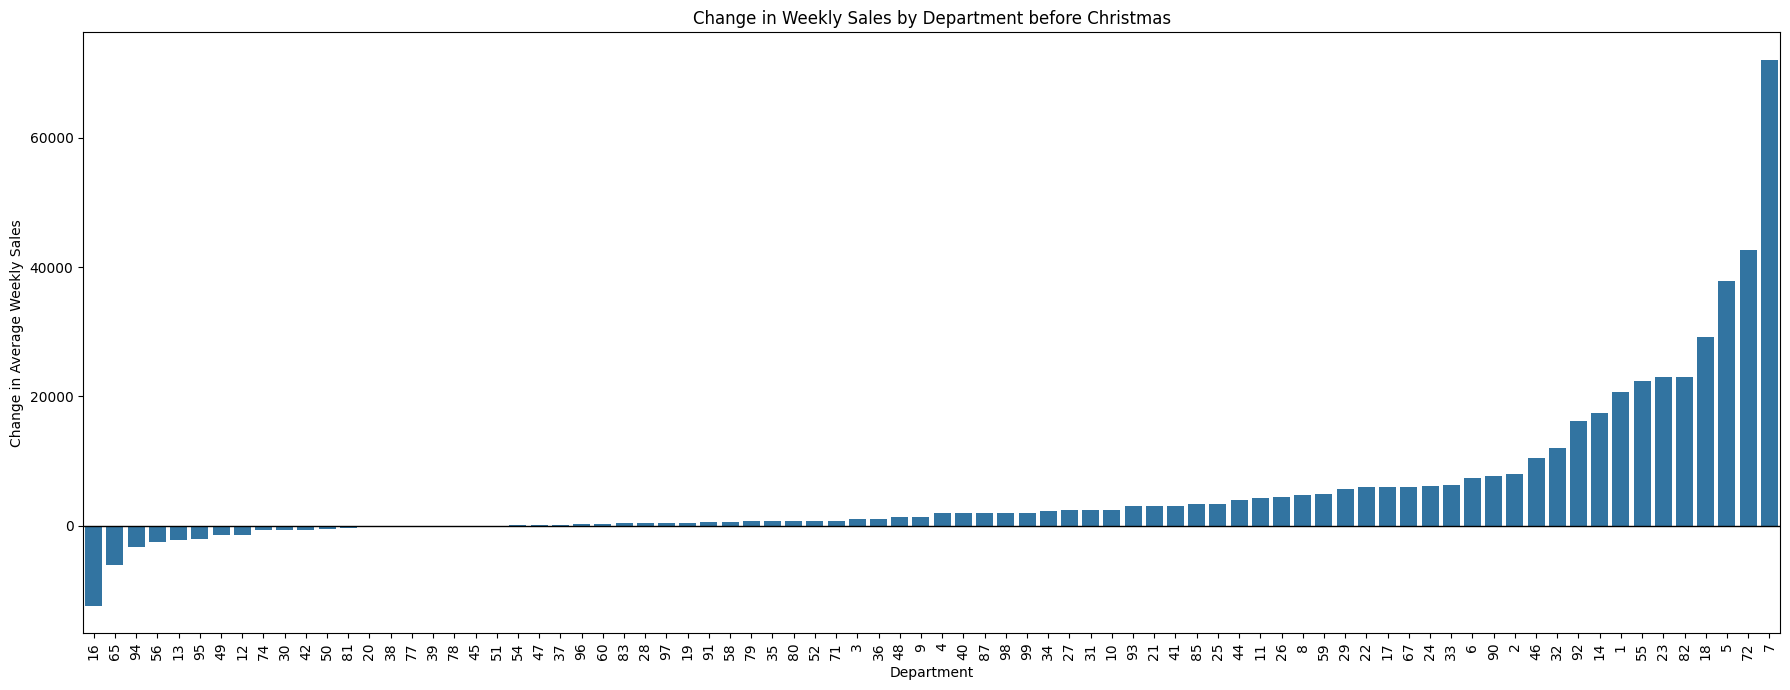

In [42]:
christmas_changes = (
    dept_christmas
    .dropna(subset=['Change_Absolute'])
    .sort_values('Change_Absolute')
    .reset_index()
)

plt.figure(figsize=(18, 7))

sns.barplot(
    data=christmas_changes,
    x='Dept',
    y='Change_Absolute',
    order=christmas_changes['Dept']
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Change in Weekly Sales by Department before Christmas')
plt.xlabel('Department')
plt.ylabel('Change in Average Weekly Sales')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [43]:
christmas_ranked = (
    dept_christmas
    .dropna(subset=['Change_Absolute'])
    .sort_values('Change_Absolute', ascending=False)
)

print('Departamentos con mayor incremento de ventas:')
display(christmas_ranked.head(10))

print('\nDepartamentos con mayor reducción de ventas:')
display(christmas_ranked.tail(10).sort_values('Change_Absolute'))

Departamentos con mayor incremento de ventas:


,Normal_Sales,Pre_Christmas_Sales,Normal_Observations,Pre_Christmas_Observations,Change_%,Change_Absolute
Dept,,,,,,
7,21627.816429,93733.308704,5715,270.0,333.392382,72105.492275
72,49065.474669,91795.423241,5367,253.0,87.087609,42729.948572
5,19817.997265,57621.829552,5634,268.0,190.755059,37803.832287
18,5813.936004,35036.798889,4312,270.0,502.634753,29222.862885
82,14515.718324,37577.470926,5715,270.0,158.874346,23061.752602
23,23305.828161,46282.799792,5138,240.0,98.588952,22976.971631
55,9718.066274,32040.312009,4971,234.0,229.698431,22322.245734
1,18651.148084,39311.325556,5715,270.0,110.771612,20660.177472
14,14180.561293,31646.381259,5715,270.0,123.167339,17465.819966



Departamentos con mayor reducción de ventas:


,Normal_Sales,Pre_Christmas_Sales,Normal_Observations,Pre_Christmas_Observations,Change_%,Change_Absolute
Dept,,,,,,
16,15593.267937,3236.551370,5715,270.0,-79.243919,-12356.716567
65,46182.930472,40173.258333,127,6.0,-13.012756,-6009.672139
94,33792.109822,30546.997089,5058,237.0,-9.603167,-3245.112733
56,4201.398923,1727.245169,5210,267.0,-58.888808,-2474.153755
13,30916.899062,28661.453778,5715,270.0,-7.295186,-2255.445284
95,70504.048135,68401.073519,5715,270.0,-2.982771,-2102.974616
49,8256.876580,6852.257526,3965,190.0,-17.011506,-1404.619054
12,4338.079845,2983.409148,5689,270.0,-31.227427,-1354.670697
74,13808.225704,13184.276259,5710,270.0,-4.518679,-623.949445


**Efecto del periodo navideño según el departamento**

El análisis del periodo previo a Navidad muestra nuevamente una respuesta muy heterogénea entre los distintos departamentos. Mientras que una parte importante presenta variaciones relativamente reducidas respecto a su comportamiento habitual, determinados departamentos experimentan incrementos muy pronunciados y otros reducen sus ventas.

Entre los mayores incrementos destaca el departamento 7, cuyas ventas medias pasan de aproximadamente 21.628 a 93.733, lo que representa un aumento superior al 330 %. También destacan los departamentos 18, 5, 55 y 82, con incrementos muy elevados tanto en términos relativos como absolutos. El departamento 72 vuelve a presentar un aumento considerable, aunque en este caso el crecimiento relativo es menor que durante Thanksgiving.

En sentido contrario, algunos departamentos experimentan una reducción de sus ventas durante las semanas previas a Navidad. El caso más destacado es el departamento 16, cuyas ventas disminuyen aproximadamente un 79 %, seguido del departamento 56, con una reducción cercana al 59 %. Otros departamentos presentan reducciones más moderadas. Nuevamente, algunos resultados deben interpretarse con precaución cuando el número de observaciones es reducido, como ocurre con el departamento 65.

La **comparación con `Thanksgiving`** permite además identificar determinados comportamientos recurrentes. Departamentos como el 5, 7, 18, 55 y 72 presentan incrementos importantes durante ambos periodos, mientras que los departamentos 16, 56 y 49 reducen sus ventas en ambos casos. Esto sugiere que determinados departamentos presentan una sensibilidad especialmente elevada, positiva o negativa, ante periodos caracterizados por fuertes cambios en la demanda.

Desde el punto de vista predictivo, estos resultados indican que el efecto de los acontecimientos estacionales depende fuertemente del departamento considerado. Por tanto, la interacción entre `Dept` y las variables temporales puede resultar especialmente relevante para los modelos. Durante la fase experimental podrá evaluarse si esta heterogeneidad puede ser aprendida adecuadamente por un modelo conjunto o si determinados patrones de comportamiento se benefician de estrategias de modelado específicas.

### 6.2. Comparación por tiendas

Ahora sumamos las ventas de todos los departamentos de cada tienda. Como las tiendas tienen tamaños y volúmenes muy distintos, comparamos principalmente el cambio porcentual: una tienda grande puede tener un cambio absoluto mayor sin que el aumento relativo sea mayor. Utilizamos las mismas definiciones de campaña y referencia que en el análisis por departamentos.

#### Thanksgiving por tienda

In [44]:
# Ventas totales de cada tienda por semana
store_weekly_sales = (
    train_merged
    .groupby(['Store', 'Date'])['Weekly_Sales']
    .sum()
    .reset_index()
)

# Identificamos las semanas de Thanksgiving
store_weekly_sales['Thanksgiving'] = (
    store_weekly_sales['Date'].isin(thanksgiving_dates)
)

# Ventas medias por tienda en semanas normales y Thanksgiving
store_thanksgiving = (
    store_weekly_sales
    .groupby(['Store', 'Thanksgiving'])['Weekly_Sales']
    .mean()
    .unstack()
    .rename(columns={
        False: 'Normal_Sales',
        True: 'Thanksgiving_Sales'
    })
)

# Cambio absoluto y porcentual
store_thanksgiving['Change_%'] = (
    (store_thanksgiving['Thanksgiving_Sales'] - store_thanksgiving['Normal_Sales'])
    / store_thanksgiving['Normal_Sales']
    * 100
)

store_thanksgiving['Change_Absolute'] = (
    store_thanksgiving['Thanksgiving_Sales']
    - store_thanksgiving['Normal_Sales']
)

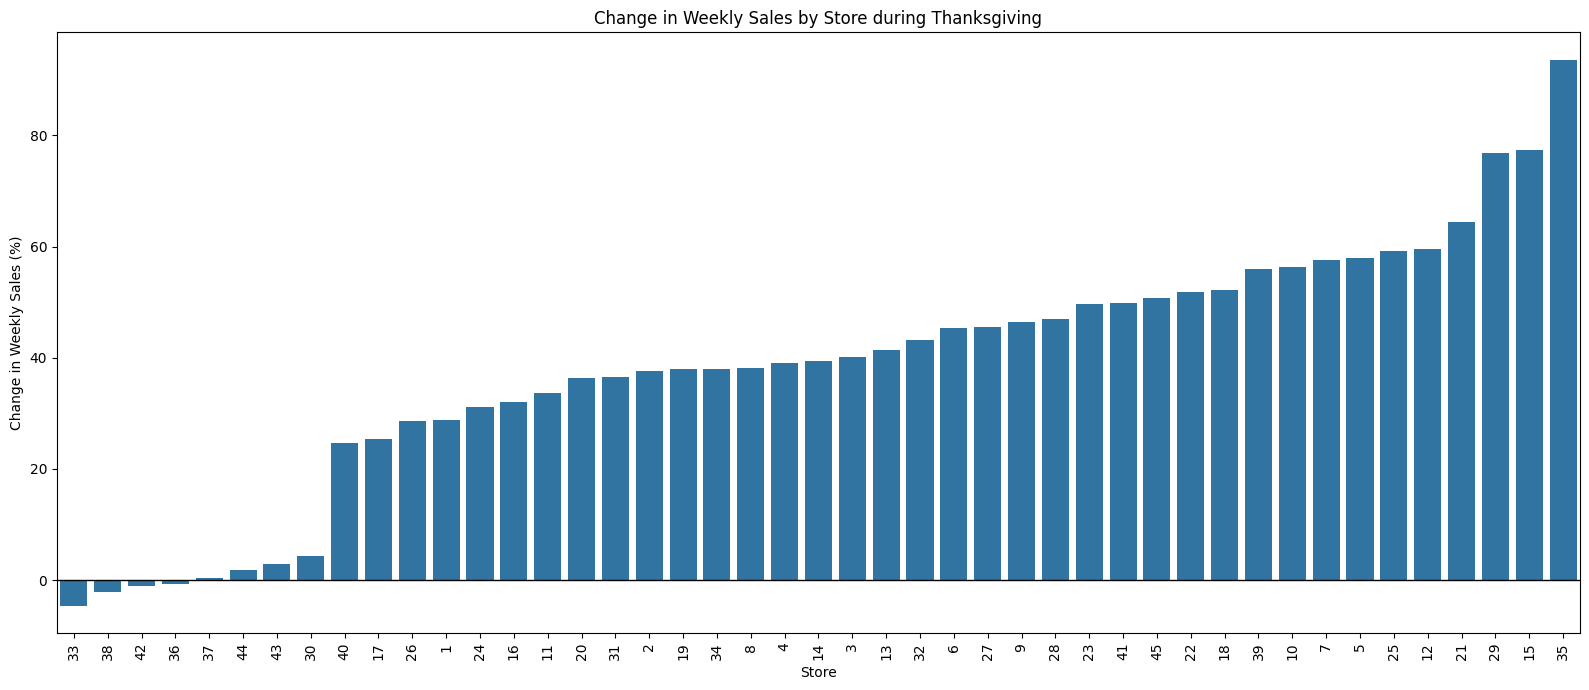

In [45]:
thanksgiving_store_changes = (
    store_thanksgiving
    .dropna(subset=['Change_Absolute'])
    .sort_values('Change_%')
    .reset_index()
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=thanksgiving_store_changes,
    x='Store',
    y='Change_%',
    order=thanksgiving_store_changes['Store']
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Change in Weekly Sales by Store during Thanksgiving')
plt.xlabel('Store')
plt.ylabel('Change in Weekly Sales (%)')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

#### Campaña navideña por tienda

In [46]:
pre_christmas_store_mask = (
    store_weekly_sales['Date'].isin(pre_christmas_dates)
)

normal_store_mask = ~store_weekly_sales['Date'].isin(
    list(pre_christmas_dates) + list(post_christmas_dates)
)

store_christmas = pd.concat(
    [
        store_weekly_sales[normal_store_mask]
        .groupby('Store')['Weekly_Sales'].mean(),

        store_weekly_sales[pre_christmas_store_mask]
        .groupby('Store')['Weekly_Sales'].mean()
    ],
    axis=1
)

store_christmas.columns = [
    'Normal_Sales',
    'Pre_Christmas_Sales'
]

store_christmas['Change_%'] = (
    (store_christmas['Pre_Christmas_Sales'] - store_christmas['Normal_Sales'])
    / store_christmas['Normal_Sales']
    * 100
)

store_christmas['Change_Absolute'] = (
    store_christmas['Pre_Christmas_Sales']
    - store_christmas['Normal_Sales']
)

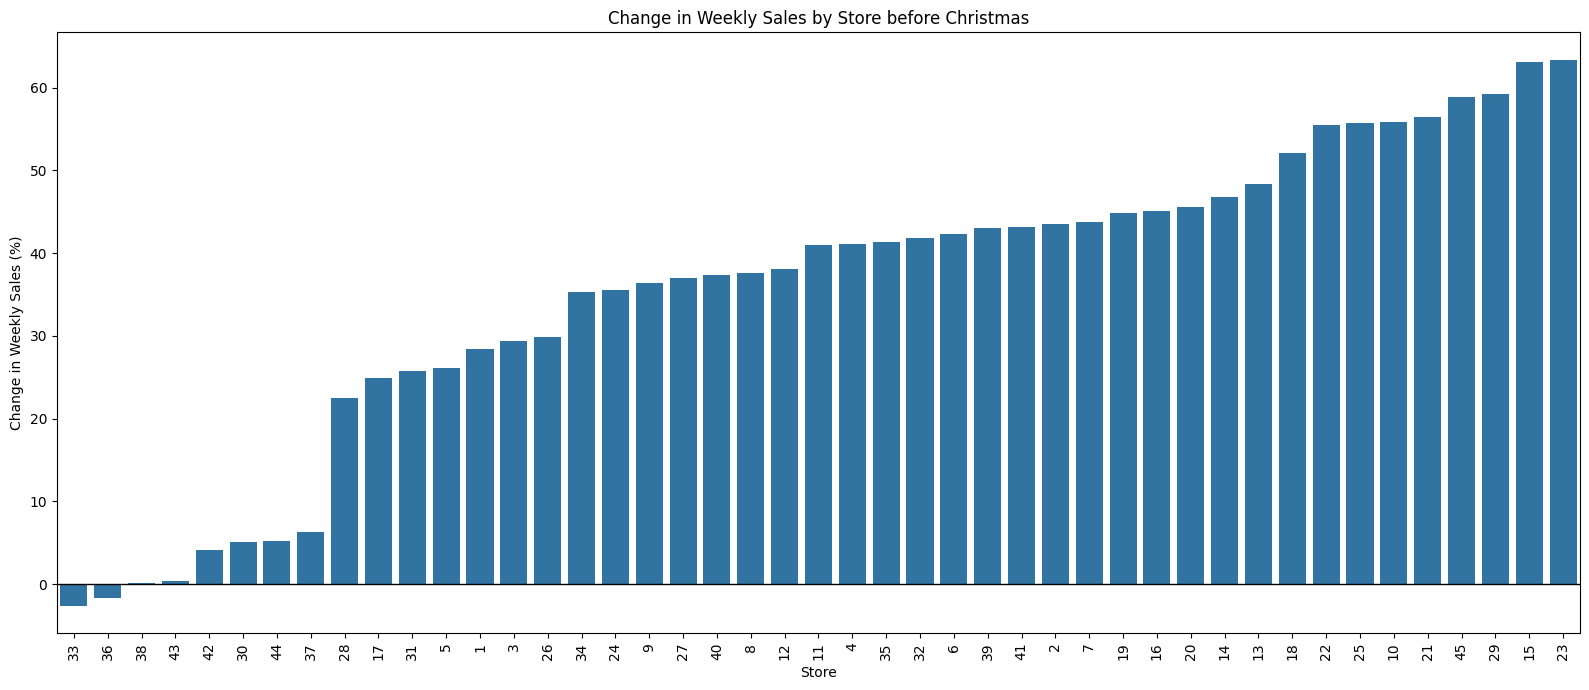

In [47]:
christmas_store_changes = (
    store_christmas
    .dropna(subset=['Change_%'])
    .sort_values('Change_%')
    .reset_index()
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=christmas_store_changes,
    x='Store',
    y='Change_%',
    order=christmas_store_changes['Store']
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Change in Weekly Sales by Store before Christmas')
plt.xlabel('Store')
plt.ylabel('Change in Weekly Sales (%)')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Efecto de las campañas según la tienda**

El análisis individual por tienda muestra que tanto Thanksgiving como el periodo previo a Navidad coinciden con un incremento considerable de las ventas en la mayoría de los establecimientos. Sin embargo, la magnitud de este incremento presenta diferencias importantes entre tiendas, existiendo establecimientos con aumentos superiores al 50 % y otros cuyo nivel de ventas apenas varía.

Además, se identifican algunas tiendas que incluso experimentan una reducción de sus ventas durante estos periodos. Aunque estos casos son minoritarios, muestran que el efecto de las campañas estacionales tampoco es completamente homogéneo a nivel de establecimiento.

Estas diferencias plantean la posibilidad de que determinadas características de las tiendas estén relacionadas con su respuesta ante los periodos de alta demanda. Por ello, a continuación se analizará si el `Type` de establecimiento permite explicar parte de la variabilidad observada entre tiendas.

### 6.3. Tipo de tienda, composición y tamaño

En el análisis inicial vimos que el tipo de tienda `A` es el que más vendía, le seguía `B` y `C` es el que menos vende en valores absolutos. También vimos que esto se relaciona con su tamaño, ya que `A` es el más grande y `C` el más pequeño.

In [48]:
# Añadimos el tipo de tienda a los resultados de ambas campañas
store_campaigns = (
    store_thanksgiving[['Change_%']]
    .rename(columns={'Change_%': 'Thanksgiving_Change_%'})
    .join(
        store_christmas[['Change_%']]
        .rename(columns={'Change_%': 'Christmas_Change_%'})
    )
    .reset_index()
    .merge(
        stores[['Store', 'Type']],
        on='Store',
        how='left'
    )
)

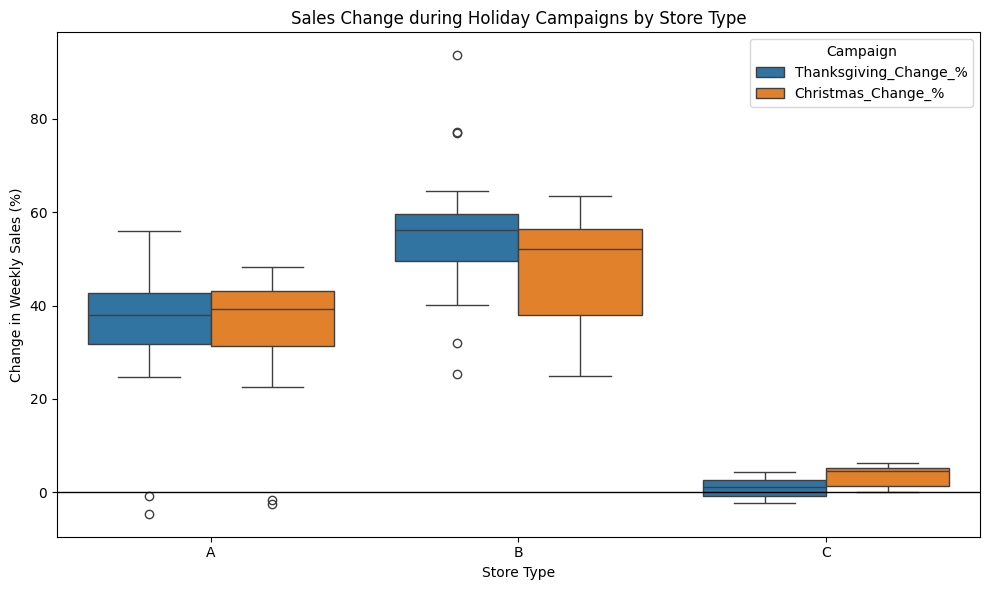

Stores  Mean_Change  Median_Change  Min_Change  \
Type Campaign                                                                
A    Christmas_Change_%         22    34.849632      39.327376   -2.589534   
     Thanksgiving_Change_%      22    35.113228      38.038822   -4.618370   
B    Christmas_Change_%         17    47.381461      52.149203   24.947496   
     Thanksgiving_Change_%      17    55.942762      56.271036   25.284562   
C    Christmas_Change_%          6     3.551583       4.645479    0.103131   
     Thanksgiving_Change_%       6     1.018244       1.090073   -2.219661   

                            Max_Change  
Type Campaign                           
A    Christmas_Change_%      48.360360  
     Thanksgiving_Change_%   55.903306  
B    Christmas_Change_%      63.384886  
     Thanksgiving_Change_%   93.630042  
C    Christmas_Change_%       6.257570  
     Thanksgiving_Change_%    4.365878

In [49]:
type_campaigns = store_campaigns.melt(
    id_vars=['Store', 'Type'],
    value_vars=['Thanksgiving_Change_%', 'Christmas_Change_%'],
    var_name='Campaign',
    value_name='Change_%'
)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=type_campaigns,
    x='Type',
    y='Change_%',
    hue='Campaign'
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Sales Change during Holiday Campaigns by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Change in Weekly Sales (%)')

plt.tight_layout()
plt.show()

type_campaign_summary = (
    type_campaigns
    .groupby(['Type', 'Campaign'])['Change_%']
    .agg(
        Stores='count',
        Mean_Change='mean',
        Median_Change='median',
        Min_Change='min',
        Max_Change='max'
    )
)

display(type_campaign_summary)

**Comparación según el tipo de tienda**

Las tiendas `B` presentan los mayores incrementos porcentuales medios en ambas campañas, seguidas de las `A`. Las tiendas `C` muestran cambios mucho más pequeños. Esto matiza la comparación de ventas absolutas: vender más en términos habituales no implica experimentar el mayor incremento relativo durante una campaña.

Vamos a revisar la composición de departamentos y el tamaño de las tiendas para contextualizar estas diferencias.

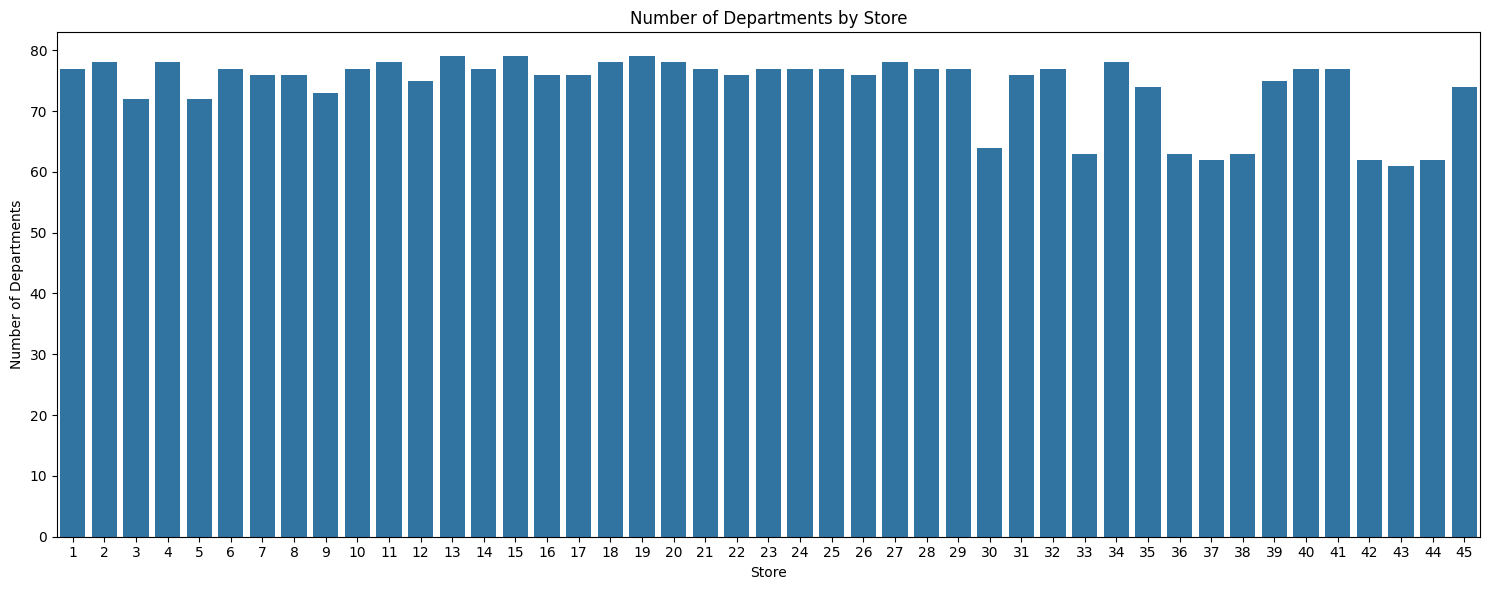

In [50]:
# Número de departamentos distintos presentes en cada tienda
departments_per_store = (
    train_merged
    .groupby('Store')['Dept']
    .nunique()
    .sort_values()
)
plt.figure(figsize=(15, 6))

sns.barplot(
    x=departments_per_store.index,
    y=departments_per_store.values
)

plt.title('Number of Departments by Store')
plt.xlabel('Store')
plt.ylabel('Number of Departments')

plt.tight_layout()
plt.show()

In [51]:
# Departamentos presentes en cada tipo de tienda
departments_by_type = (
    train_merged
    .groupby('Type')['Dept']
    .apply(lambda x: set(x.unique()))
)

for store_type, departments in departments_by_type.items():
  print(f'Tipo {store_type}: {len(departments)} departamentos')

# Departamentos exclusivos de cada tipo
only_A = departments_by_type['A'] - departments_by_type['B'] - departments_by_type['C']
only_B = departments_by_type['B'] - departments_by_type['A'] - departments_by_type['C']
only_C = departments_by_type['C'] - departments_by_type['A'] - departments_by_type['B']

AyB = departments_by_type['A'] & departments_by_type['B']
AyC = departments_by_type['A'] & departments_by_type['C']
ByC = departments_by_type['B'] & departments_by_type['C']

# Departamentos compartidos por los tres tipos
common_all = departments_by_type['A']& departments_by_type['B']& departments_by_type['C']

print('Departamentos comunes a A, B y C:')
print(len(common_all))

print('Departamentos comunes de A y B')
print(len(AyB))

print('Departamentos comunes de A y C')
print(len(AyC))

print('Departamentos comunes de B y C')
print(len(ByC))

print('Exclusivos de A:')
print(len(only_A))

print('Exclusivos de B:')
print(len(only_B))

print('Exclusivos de C:')
print(len(only_C))

Tipo A: 81 departamentos
Tipo B: 80 departamentos
Tipo C: 66 departamentos
Departamentos comunes a A, B y C:
66
Departamentos comunes de A y B
80
Departamentos comunes de A y C
66
Departamentos comunes de B y C
66
Exclusivos de A:
1
Exclusivos de B:
0
Exclusivos de C:
0


**Composición de departamentos según el tipo de tienda**

El análisis de la composición de los establecimientos muestra diferencias en el número de departamentos presentes según el tipo de tienda. Consideradas en conjunto, las tiendas de tipo A incluyen 81 departamentos distintos, las de tipo B 80 y las de tipo C 66; no significa que cada tienda individual tenga todos ellos.

Los 66 departamentos presentes en las tiendas de tipo C aparecen también en los tipos A y B, mientras que los 80 departamentos del tipo B están presentes en las tiendas de tipo A. Únicamente existe un departamento adicional exclusivo del tipo A. Por tanto, la composición de departamentos presenta una estructura prácticamente anidada:

$$
Dept_C \subset Dept_B \subset Dept_A
$$

con 66, 80 y 81 departamentos, respectivamente.

Esto indica que los departamentos de las tiendas C forman un subconjunto de los presentes en A y B, aunque su peso en las ventas puede ser diferente. Este resultado resulta relevante para interpretar su menor respuesta durante Thanksgiving y Navidad, ya que parte de esta diferencia podría estar relacionada con la ausencia de determinados departamentos. Para explorar esta posibilidad, calculamos a continuación cuánto pesan en las ventas de A y B los departamentos que no están presentes en C.

In [52]:
# Departamentos presentes en A y B, pero no en C
AB_not_C = (
    departments_by_type['A']
    & departments_by_type['B']
) - departments_by_type['C']

# Ventas totales por departamento para los grupos de interés
sales_only_A = (
    train_merged[
        train_merged['Dept'].isin(only_A)
    ]
    .groupby('Dept')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

sales_AB_not_C = (
    train_merged[
        train_merged['Dept'].isin(AB_not_C)
    ]
    .groupby('Dept')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

print('Departamento exclusivo de A:')
display(sales_only_A)

print('\nDepartamentos presentes en A y B, pero no en C:')
display(sales_AB_not_C)

Departamento exclusivo de A:


,Weekly_Sales
Dept,
65,6498163.99



Departamentos presentes en A y B, pero no en C:


,Weekly_Sales
Dept,
30,21789381.43
58,16255763.57
36,10709513.77
37,8017243.35
50,4153197.13
48,2342804.61
54,516294.63
77,49344.27
45,44937.63


In [53]:
# Ventas totales de cada tipo de tienda
total_sales_by_type = (
    train_merged
    .groupby('Type')['Weekly_Sales']
    .sum()
)

# Peso del departamento exclusivo de A sobre las ventas de las tiendas A
only_A_sales = train_merged.loc[
    (train_merged['Type'] == 'A') &
    (train_merged['Dept'].isin(only_A)),
    'Weekly_Sales'
].sum()

only_A_share = only_A_sales / total_sales_by_type['A'] * 100

print(
    f'Peso del departamento exclusivo de A sobre las ventas de A: '
    f'{only_A_share:.2f}%'
)

# Peso de los departamentos presentes en A y B, pero no en C
for store_type in ['A', 'B']:

    dept_sales = train_merged.loc[
        (train_merged['Type'] == store_type) &
        (train_merged['Dept'].isin(AB_not_C)),
        'Weekly_Sales'
    ].sum()

    share = dept_sales / total_sales_by_type[store_type] * 100

    print(
        f'Peso de los departamentos A-B ausentes en C sobre las ventas de {store_type}: '
        f'{share:.2f}%'
    )

Peso del departamento exclusivo de A sobre las ventas de A: 0.15%
Peso de los departamentos A-B ausentes en C sobre las ventas de A: 0.95%
Peso de los departamentos A-B ausentes en C sobre las ventas de B: 1.13%


**Importancia de los departamentos no presentes en las tiendas de tipo C**

Aunque las tiendas de tipo C presentan una menor variedad de departamentos, los departamentos ausentes tienen un peso reducido sobre las ventas totales de los otros tipos de establecimiento. Los 14 departamentos presentes en los tipos A y B pero ausentes en C representan únicamente el 0,95 % de las ventas totales de las tiendas A y el 1,13 % de las tiendas B.

Asimismo, el departamento 65, único departamento presente exclusivamente en las tiendas de tipo A, representa apenas el 0,15 % de las ventas de este tipo de establecimiento.

Por tanto, aunque existen diferencias en la composición departamental entre los tipos de tienda, los departamentos adicionales de A y B representan una proporción pequeña de sus ventas totales. Esto sugiere que la menor variedad de departamentos de las tiendas C difícilmente puede explicar por sí sola las diferencias de comportamiento observadas entre los distintos tipos de establecimiento.

In [54]:
# Datos correspondientes a Thanksgiving
thanksgiving_sales = train_merged[
    train_merged['Date'].isin(thanksgiving_dates)
]

for store_type in ['A', 'B']:

    # Ventas totales del tipo durante Thanksgiving
    total = thanksgiving_sales.loc[
        thanksgiving_sales['Type'] == store_type,
        'Weekly_Sales'
    ].sum()

    # Ventas de los departamentos A-B que no existen en C
    missing_depts_sales = thanksgiving_sales.loc[
        (thanksgiving_sales['Type'] == store_type) &
        (thanksgiving_sales['Dept'].isin(AB_not_C)),
        'Weekly_Sales'
    ].sum()

    share = missing_depts_sales / total * 100

    print(
        f'Peso de los departamentos A-B ausentes en C durante Thanksgiving '
        f'en tiendas {store_type}: {share:.2f}%'
    )

Peso de los departamentos A-B ausentes en C durante Thanksgiving en tiendas A: 0.82%
Peso de los departamentos A-B ausentes en C durante Thanksgiving en tiendas B: 0.78%


In [55]:
# Datos correspondientes a las tres semanas previas a Navidad
christmas_sales = train_merged[
    train_merged['Date'].isin(pre_christmas_dates)
]

for store_type in ['A', 'B']:

    # Ventas totales del tipo durante el periodo prenavideño
    total = christmas_sales.loc[
        christmas_sales['Type'] == store_type,
        'Weekly_Sales'
    ].sum()

    # Ventas de los departamentos A-B que no existen en C
    missing_depts_sales = christmas_sales.loc[
        (christmas_sales['Type'] == store_type) &
        (christmas_sales['Dept'].isin(AB_not_C)),
        'Weekly_Sales'
    ].sum()

    share = missing_depts_sales / total * 100

    print(
        f'Peso de los departamentos A-B ausentes en C durante Navidad '
        f'en tiendas {store_type}: {share:.2f}%'
    )

Peso de los departamentos A-B ausentes en C durante Navidad en tiendas A: 0.82%
Peso de los departamentos A-B ausentes en C durante Navidad en tiendas B: 0.85%


**Influencia de la composición departamental durante las campañas**

Para comprobar si la menor respuesta de las tiendas de tipo C durante Thanksgiving y Navidad podía estar relacionada con su menor variedad de departamentos, se analizó el peso de los 14 departamentos presentes en los tipos A y B pero ausentes en C.

En el conjunto completo, estos departamentos representan únicamente el 0,95 % de las ventas de las tiendas A y el 1,13 % de las tiendas B. Además, su importancia no aumenta durante los periodos de mayor demanda. Durante Thanksgiving representan el 0,82 % y el 0,78 % de las ventas de A y B, respectivamente, mientras que durante el periodo previo a Navidad suponen el 0,82 % y el 0,85 %.

Por tanto, la menor respuesta estacional observada en las tiendas de tipo C no parece explicarse por la ausencia de estos departamentos. Los incrementos registrados en A y B durante Thanksgiving y Navidad proceden principalmente de departamentos que también están presentes en las tiendas C.

Este resultado refuerza la hipótesis de que el tipo de establecimiento, o alguna característica asociada a este, está relacionado con diferencias en la respuesta ante los periodos de alta demanda. No obstante, esta relación no debe interpretarse todavía como causal, por lo que será necesario considerar otras características de las tiendas, como su tamaño.

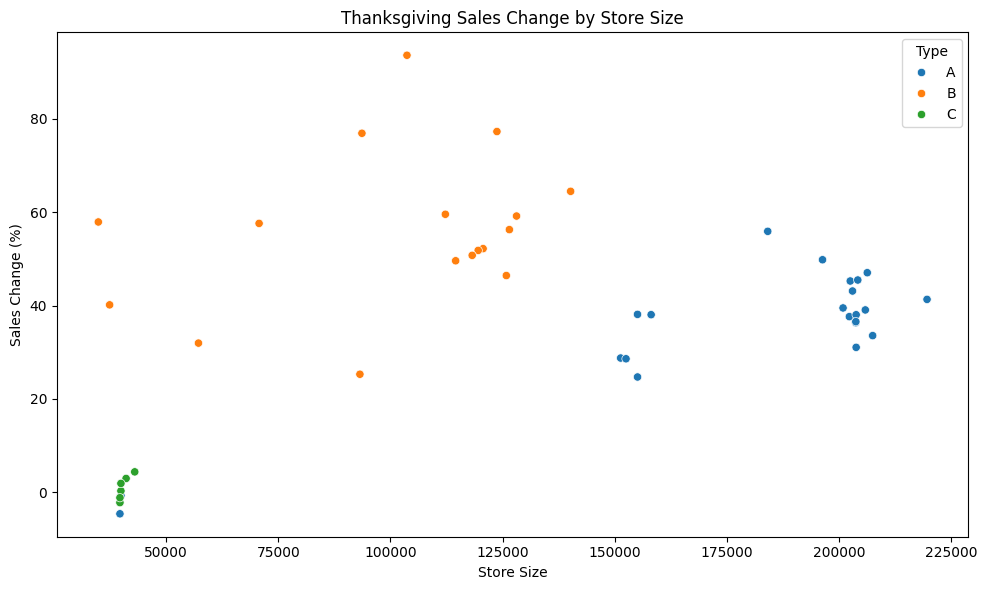

In [56]:
# Incorporamos el tamaño de cada tienda a los cambios observados
store_campaigns_size = (
    store_campaigns
    .merge(
        stores[['Store', 'Size']],
        on='Store',
        how='left'
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=store_campaigns_size,
    x='Size',
    y='Thanksgiving_Change_%',
    hue='Type',
    ax=ax
)

plt.title('Thanksgiving Sales Change by Store Size')
plt.xlabel('Store Size')
plt.ylabel('Sales Change (%)')

plt.tight_layout()
plt.show()

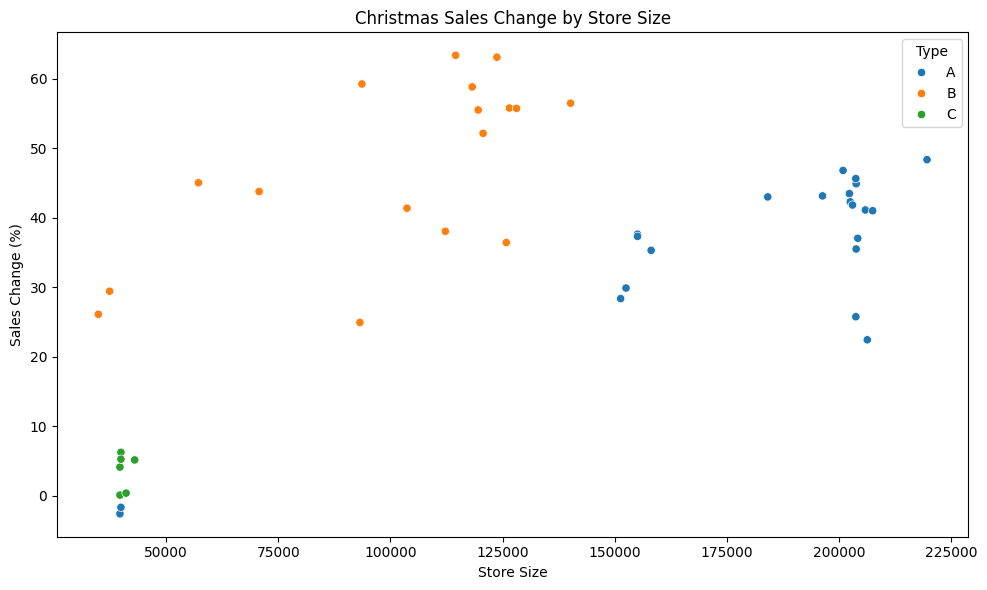

In [57]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=store_campaigns_size,
    x='Size',
    y='Christmas_Change_%',
    hue='Type'
)

plt.title('Christmas Sales Change by Store Size')
plt.xlabel('Store Size')
plt.ylabel('Sales Change (%)')

plt.tight_layout()
plt.show()

**Relación entre el tamaño de la tienda y la respuesta a las campañas**

Dado que los tipos de tienda tienen tamaños medios distintos, comprobamos cómo se relaciona `Size` con los cambios porcentuales durante las dos campañas.

Los gráficos no muestran que un mayor tamaño implique necesariamente un mayor incremento relativo. Las tiendas `C`, de menor tamaño, presentan variaciones reducidas, pero los mayores incrementos se observan generalmente en las `B`, de tamaño intermedio. Las tiendas `A` tienen mayor tamaño y cambios más moderados que las `B`.

Ambas representaciones muestran un patrón parecido. El tamaño, el tipo de tienda y la composición de departamentos están relacionados, por lo que estas comparaciones no permiten separar sus aportaciones. Conservamos `Type` y `Size` en los datos procesados. La idea de comparar modelos con y sin `Size` queda como una posibilidad exploratoria, no como un experimento realizado en este notebook.

## 7. Composición y concentración de las ventas

Tras comparar las campañas, volvemos al conjunto de semanas para estudiar cómo se distribuyen las ventas dentro de cada tipo de tienda. Primero utilizamos observaciones semanales por tienda y departamento; después calculamos el peso de cada departamento en las ventas totales y en la cola superior de la distribución.

In [58]:
type_sales_summary = (
    train_merged
    .groupby('Type')['Weekly_Sales']
    .agg(
        Observations='count',
        Mean='mean',
        Median='median',
        Std='std',
        Min='min',
        Max='max'
    )
)

# Añadimos percentiles para caracterizar mejor la cola superior
type_sales_summary['P90'] = (
    train_merged.groupby('Type')['Weekly_Sales'].quantile(0.90)
)

type_sales_summary['P95'] = (
    train_merged.groupby('Type')['Weekly_Sales'].quantile(0.95)
)

type_sales_summary['P99'] = (
    train_merged.groupby('Type')['Weekly_Sales'].quantile(0.99)
)

display(type_sales_summary)

,Observations,Mean,Median,Std,Min,Max,P90,P95,P99
Type,,,,,,,,,
A,215478,20099.568043,10105.17,26423.457227,-4988.94,474330.10,53172.673,74285.733,126175.3550
B,163495,12237.075977,6187.87,17203.668989,-3924.00,693099.36,32101.396,46279.641,77292.3458
C,42597,9519.532538,1149.67,15985.351612,-379.00,112152.35,31192.280,46833.022,72103.3664


**Caracterización de las ventas según el tipo de tienda**

Las distribuciones de ventas presentan diferencias claras entre los tres tipos de establecimiento. Las tiendas de tipo A muestran los mayores niveles de venta tanto en términos medios como en los percentiles superiores, por lo que concentran de forma más consistente las observaciones de mayor volumen.

Las tiendas de tipo B presentan valores habituales inferiores a los de A, aunque contienen la observación máxima de todo el conjunto. Sin embargo, sus percentiles superiores son considerablemente menores que los de A, lo que indica que este máximo responde a un comportamiento excepcional más que a una tendencia general.

Las tiendas de tipo C presentan el comportamiento más asimétrico. Su mediana es muy reducida en comparación con su media, mientras que sus percentiles 95 y 99 son relativamente próximos a los observados en B. Esto sugiere la existencia de numerosas observaciones con ventas bajas junto con un conjunto reducido de departamentos u observaciones con ventas considerablemente superiores.

Por este motivo, resulta interesante analizar a continuación cómo se distribuyen las ventas entre los distintos departamentos dentro de cada tipo de tienda, con el objetivo de comprobar si determinados departamentos concentran una parte importante de las ventas.

In [59]:
# Ventas totales por departamento dentro de cada tipo de tienda
dept_sales_by_type = (
    train_merged
    .groupby(['Type', 'Dept'])['Weekly_Sales']
    .sum()
    .reset_index()
)

# Ventas totales de cada tipo
type_total_sales = (
    dept_sales_by_type
    .groupby('Type')['Weekly_Sales']
    .transform('sum')
)

# Peso de cada departamento dentro de las ventas de su tipo
dept_sales_by_type['Sales_Share_%'] = (
    dept_sales_by_type['Weekly_Sales']
    / type_total_sales
    * 100
)

# Mostramos los departamentos con mayor peso dentro de cada tipo
for store_type in ['A', 'B', 'C']:
    print(f'Tipo {store_type}:')

    display(
        dept_sales_by_type[
            dept_sales_by_type['Type'] == store_type
        ]
        .sort_values('Sales_Share_%', ascending=False)
        .head(10)
    )

Tipo A:


,Type,Dept,Weekly_Sales,Sales_Share_%
73,A,92,3.528455e+08,8.146949
76,A,95,3.054578e+08,7.052800
71,A,90,2.219519e+08,5.124709
36,A,38,2.045058e+08,4.721891
60,A,72,1.785082e+08,4.121626
72,A,91,1.690476e+08,3.903187
38,A,40,1.687679e+08,3.896728
1,A,2,1.635752e+08,3.776834
75,A,94,1.606569e+08,3.709452
74,A,93,1.362110e+08,3.145013


Tipo B:


,Type,Dept,Weekly_Sales,Sales_Share_%
117,B,38,1.417301e+08,7.084025
140,B,72,1.271272e+08,6.354135
82,B,2,1.046594e+08,5.231137
119,B,40,1.029907e+08,5.147730
156,B,95,1.004119e+08,5.018836
153,B,92,7.893503e+07,3.945369
93,B,13,6.838739e+07,3.418172
88,B,8,6.704433e+07,3.351042
102,B,23,6.324977e+07,3.161381
87,B,7,5.813915e+07,2.905939


Tipo C:


,Type,Dept,Weekly_Sales,Sales_Share_%
219,C,92,52162761.54,12.863701
194,C,38,46882211.29,11.561481
222,C,95,43450462.66,10.715187
217,C,90,37433022.26,9.231245
221,C,94,27143838.06,6.693860
218,C,91,26275291.18,6.479670
220,C,93,20442952.50,5.041375
195,C,40,17177474.40,4.236085
223,C,96,13527249.82,3.335914
162,C,2,12376522.77,3.052137


In [60]:
# Peso acumulado de los departamentos con mayores ventas dentro de cada tipo
for store_type in ['A', 'B', 'C']:

    shares = (
        dept_sales_by_type[
            dept_sales_by_type['Type'] == store_type
        ]
        .sort_values('Sales_Share_%', ascending=False)['Sales_Share_%']
    )

    print(
        f'Tipo {store_type} | '
        f'Top 3: {shares.head(3).sum():.2f}% | '
        f'Top 5: {shares.head(5).sum():.2f}% | '
        f'Top 10: {shares.head(10).sum():.2f}%'
    )

Tipo A | Top 3: 20.32% | Top 5: 29.17% | Top 10: 47.60%
Tipo B | Top 3: 18.67% | Top 5: 28.84% | Top 10: 45.62%
Tipo C | Top 3: 35.14% | Top 5: 51.07% | Top 10: 73.21%


### 7.1. Departamentos dominantes y cola superior

In [61]:
for store_type in ['A', 'B','C']:

    # Seleccionamos las observaciones del tipo de tienda
    type_sales = train_merged[
        train_merged['Type'] == store_type
    ]

    # Umbral del 5 % de ventas más altas
    p95 = type_sales['Weekly_Sales'].quantile(0.95)

    # Observaciones situadas en la cola superior
    high_sales = type_sales[
        type_sales['Weekly_Sales'] >= p95
    ]

    # Departamentos responsables de las ventas superiores al P95
    high_sales_by_dept = (
        high_sales
        .groupby('Dept')
        .agg(
            Observations=('Weekly_Sales', 'size'),
            Total_Sales=('Weekly_Sales', 'sum'),
            Mean_Sales=('Weekly_Sales', 'mean')
        )
        .sort_values('Observations', ascending=False)
    )

    # Peso de cada departamento dentro de la cola superior
    high_sales_by_dept['Observation_Share_%'] = (
        high_sales_by_dept['Observations']
        / len(high_sales)
        * 100
    )

    print(f'\nTipo {store_type} - P95: {p95:.2f}')
    display(high_sales_by_dept.head(15))


Tipo A - P95: 74285.73


,Observations,Total_Sales,Mean_Sales,Observation_Share_%
Dept,,,,
92,2512,3.192105e+08,127074.261250,23.315389
95,2317,2.603384e+08,112360.106439,21.505476
90,1345,1.268952e+08,94345.874126,12.483757
38,1227,1.130018e+08,92095.996349,11.388528
72,626,6.966733e+07,111289.662620,5.810284
2,572,4.823310e+07,84323.608269,5.309077
91,564,4.768213e+07,84542.789096,5.234825
40,554,4.512555e+07,81454.056986,5.142009
94,292,2.333628e+07,79918.779658,2.710228



Tipo B - P95: 46279.64


,Observations,Total_Sales,Mean_Sales,Observation_Share_%
Dept,,,,
38,1611,1.101762e+08,68389.956965,19.706422
72,1027,8.556156e+07,83312.136650,12.562691
95,943,5.459261e+07,57892.481516,11.535168
2,866,6.114502e+07,70606.256605,10.593272
40,777,5.004080e+07,64402.576937,9.504587
92,634,3.560256e+07,56155.458549,7.755352
9,283,1.778292e+07,62837.168233,3.461774
23,277,1.718224e+07,62029.761336,3.388379
13,268,1.506114e+07,56198.279813,3.278287



Tipo C - P95: 46833.02


,Observations,Total_Sales,Mean_Sales,Observation_Share_%
Dept,,,,
92,622,42660813.23,68586.516447,29.201878
38,568,35391708.25,62309.345511,26.666667
95,489,29508386.64,60344.348957,22.957746
90,290,17010255.77,58656.054379,13.615023
94,110,5829835.44,52998.504000,5.164319
91,48,2407339.65,50152.909375,2.253521
1,1,70912.01,70912.010000,0.046948
79,1,83190.30,83190.300000,0.046948
93,1,46882.67,46882.670000,0.046948


**Departamentos responsables de las ventas elevadas según el tipo de tienda**

El análisis de las observaciones situadas por encima del percentil 95 muestra que las ventas elevadas se concentran en un número reducido de departamentos en los tres tipos de establecimiento. Sin embargo, esta concentración es especialmente acusada en las tiendas de tipo C.

En las tiendas A, los cuatro departamentos con mayor presencia en la cola superior (`92`, `95`, `90` y `38`) concentran aproximadamente el 69 % de las observaciones superiores al P95. En las tiendas B, los seis departamentos principales concentran alrededor del 72 %. En las tiendas C(`92`, `38`, `95`, `90`, `94` y `91`), esta concentración es mucho más extrema, ya que seis departamentos explican prácticamente la totalidad de las observaciones situadas por encima de su P95.

Además, existe un importante solapamiento entre los departamentos responsables de las ventas elevadas. Los departamentos `38`, `92` y `95` destacan en los tres tipos de tienda, lo que sugiere que determinadas categorías presentan un comportamiento de ventas elevado de forma relativamente consistente. No obstante, su importancia relativa varía según el tipo de establecimiento.

Por tanto, aunque la concentración de ventas elevadas en determinados departamentos es un patrón general del conjunto de datos, las tiendas de tipo C presentan una dependencia mucho mayor de un número reducido de departamentos.

In [62]:
p95_dept_results = []

for store_type in ['A', 'B', 'C']:

    type_sales = train_merged[
        train_merged['Type'] == store_type
    ]

    p95 = type_sales['Weekly_Sales'].quantile(0.95)

    high_sales = type_sales[
        type_sales['Weekly_Sales'] >= p95
    ]

    high_sales_by_dept = (
        high_sales
        .groupby('Dept')
        .agg(
            P95_Observations=('Weekly_Sales', 'size'),
            P95_Mean_Sales=('Weekly_Sales', 'mean'),
            P95_Max_Sales=('Weekly_Sales', 'max')
        )
        .reset_index()
    )

    high_sales_by_dept['P95_Observation_Share_%'] = (
        high_sales_by_dept['P95_Observations']
        / len(high_sales) * 100
    )

    high_sales_by_dept['Type'] = store_type

    p95_dept_results.append(high_sales_by_dept)

p95_dept_by_type = pd.concat(
    p95_dept_results,
    ignore_index=True
)

In [63]:
dept_importance = (
    dept_sales_by_type[
        ['Type', 'Dept', 'Sales_Share_%']
    ]
    .merge(
        p95_dept_by_type,
        on=['Type', 'Dept'],
        how='left'
    )
    .fillna({
        'P95_Observations': 0,
        'P95_Observation_Share_%': 0
    })
)

# Principales departamentos según su peso en las ventas totales
for store_type in ['A', 'B', 'C']:

    print(f'\nTipo {store_type}')

    display(
        dept_importance[
            dept_importance['Type'] == store_type
        ]
        .sort_values('Sales_Share_%', ascending=False)
        .head(10)
    )


Tipo A


,Type,Dept,Sales_Share_%,P95_Observations,P95_Mean_Sales,P95_Max_Sales,P95_Observation_Share_%
73,A,92,8.146949,2512.0,127074.261250,293966.05,23.315389
76,A,95,7.052800,2317.0,112360.106439,213042.66,21.505476
71,A,90,5.124709,1345.0,94345.874126,166263.81,12.483757
36,A,38,4.721891,1227.0,92095.996349,172794.20,11.388528
60,A,72,4.121626,626.0,111289.662620,474330.10,5.810284
72,A,91,3.903187,564.0,84542.789096,162497.78,5.234825
38,A,40,3.896728,554.0,81454.056986,101700.89,5.142009
1,A,2,3.776834,572.0,84323.608269,131234.40,5.309077
75,A,94,3.709452,292.0,79918.779658,103929.39,2.710228
74,A,93,3.145013,158.0,80698.694747,103827.72,1.466493



Tipo B


,Type,Dept,Sales_Share_%,P95_Observations,P95_Mean_Sales,P95_Max_Sales,P95_Observation_Share_%
117,B,38,7.084025,1611.0,68389.956965,155897.94,19.706422
140,B,72,6.354135,1027.0,83312.136650,693099.36,12.562691
82,B,2,5.231137,866.0,70606.256605,151090.50,10.593272
119,B,40,5.147730,777.0,64402.576937,119463.15,9.504587
156,B,95,5.018836,943.0,57892.481516,115565.70,11.535168
153,B,92,3.945369,634.0,56155.458549,105950.68,7.755352
93,B,13,3.418172,268.0,56198.279813,74020.63,3.278287
88,B,8,3.351042,157.0,83317.110955,103627.76,1.920489
102,B,23,3.161381,277.0,62029.761336,165214.36,3.388379
87,B,7,2.905939,208.0,82567.772596,406988.63,2.544343



Tipo C


,Type,Dept,Sales_Share_%,P95_Observations,P95_Mean_Sales,P95_Max_Sales,P95_Observation_Share_%
219,C,92,12.863701,622.0,68586.516447,112152.35,29.201878
194,C,38,11.561481,568.0,62309.345511,100618.04,26.666667
222,C,95,10.715187,489.0,60344.348957,94764.38,22.957746
217,C,90,9.231245,290.0,58656.054379,78137.86,13.615023
221,C,94,6.693860,110.0,52998.504000,69672.87,5.164319
218,C,91,6.479670,48.0,50152.909375,54379.70,2.253521
220,C,93,5.041375,1.0,46882.670000,46882.67,0.046948
195,C,40,4.236085,0.0,NaN,NaN,0.000000
223,C,96,3.335914,0.0,NaN,NaN,0.000000
162,C,2,3.052137,0.0,NaN,NaN,0.000000


**Relación entre los departamentos dominantes y las ventas elevadas**

El análisis conjunto del peso de cada departamento sobre las ventas totales y de su comportamiento por encima del percentil 95 permite identificar diferencias adicionales entre los tipos de establecimiento.

En las tiendas de tipo A, los departamentos `92` y `95` presentan una elevada presencia en la cola superior y niveles de venta consistentemente altos. No obstante, el máximo del tipo A corresponde al departamento `72`, con unas ventas semanales de 474.330, considerablemente superiores a su propia media entre las observaciones situadas por encima del P95.

En las tiendas de tipo B, las ventas elevadas se encuentran algo más distribuidas entre departamentos. Destaca especialmente el departamento `72`, que alcanza un máximo de 693.099, pese a presentar una media de aproximadamente 83.000 entre sus observaciones superiores al P95. El departamento `7` presenta un comportamiento similar, con un máximo próximo a 407.000. Por tanto, los elevados máximos observados en las tiendas B parecen estar asociados a episodios excepcionalmente altos en determinados departamentos, y no a un nivel de ventas generalmente superior.

Las tiendas de tipo C presentan un comportamiento diferente. Sus ventas elevadas se encuentran fuertemente concentradas en los departamentos `92`, `38`, `95` y `90`, pero los máximos alcanzados son considerablemente menores. En este caso existe una mayor correspondencia entre los departamentos que sostienen el volumen total de ventas y aquellos que dominan la cola superior de la distribución.

En conjunto, las tiendas A se caracterizan por niveles de venta elevados de forma más consistente, las tiendas B por la aparición de algunos episodios de venta excepcionalmente altos y las tiendas C por una fuerte concentración de sus ventas en un conjunto reducido de departamentos.

## 8. Relación entre las variables explicativas y las ventas

### 8.1. Correlaciones numéricas

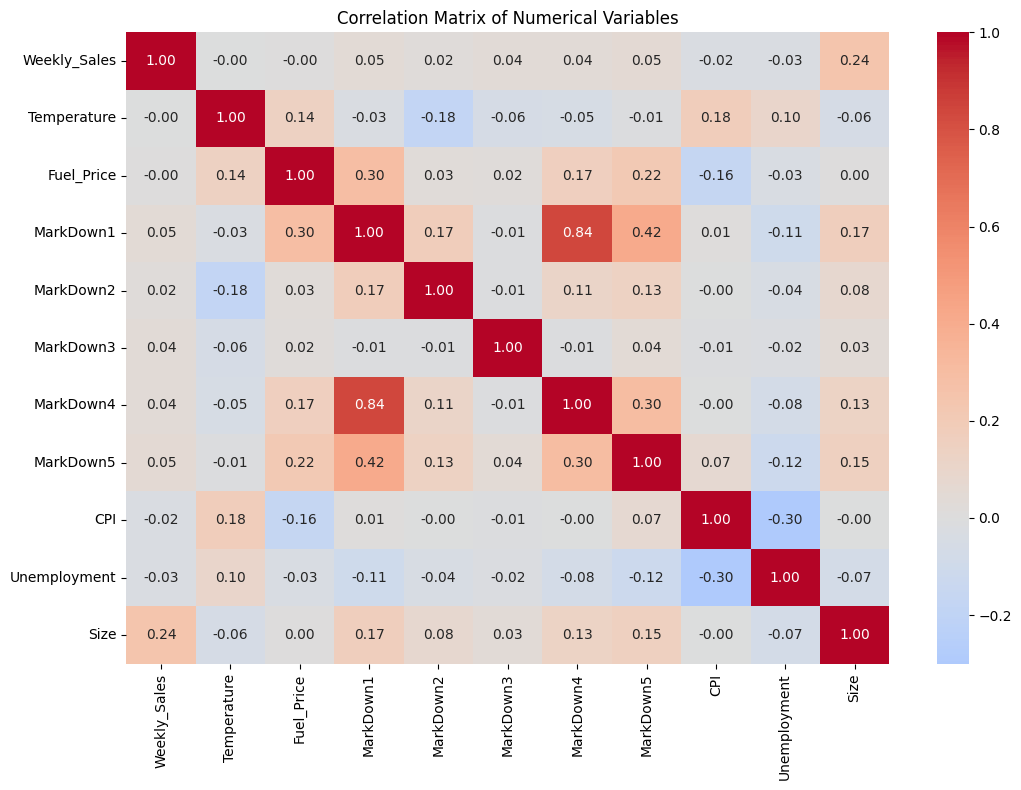

In [64]:
numeric_cols = [
    'Weekly_Sales',
    'Temperature',
    'Fuel_Price',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5',
    'CPI',
    'Unemployment',
    'Size'
]

correlation_matrix = train_merged[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

La matriz de correlaciones muestra que ninguna de las variables numéricas presenta una relación lineal fuerte con `Weekly_Sales`. La asociación más elevada corresponde a `Size` ($r=0.24$), mientras que variables como `Temperature`, `Fuel_Price`, `CPI`, `Unemployment` y los distintos `MarkDown` presentan correlaciones lineales muy reducidas con las ventas.

Esto no implica necesariamente una baja capacidad predictiva de estas variables, ya que pueden existir relaciones no lineales o interacciones con otras características como la tienda, el departamento o el periodo temporal. Por este motivo, no se descartan variables a partir de este análisis.

Entre las variables explicativas destaca la elevada correlación entre `MarkDown1` y `MarkDown4` ($r=0.84$), lo que sugiere cierto grado de información compartida entre ambas variables promocionales. Esta asociación queda identificada, pero aquí se mantienen ambas variables.

La matriz utiliza los `MarkDown` después de rellenar sus ausencias con cero. Para distinguir la disponibilidad del valor observado de la promoción, en el siguiente apartado recuperamos los indicadores `_isna`.

### 8.2. Disponibilidad e intensidad de los `MarkDown`

Primero comparamos las ventas según estuviera disponible o no cada variable promocional. Después estudiamos únicamente sus valores originalmente observados y los agrupamos en cuartiles. Estas variables están definidas por tienda y fecha y se repiten en los departamentos: las tablas siguientes resumen observaciones de ventas, no promociones independientes.

In [65]:
markdown_sales_summary = []

for col in markdown_cols:
    summary = (
        train_merged
        .assign(MarkDown_Available=~train_merged[f'{col}_isna'])
        .groupby('MarkDown_Available')['Weekly_Sales']
        .agg(
            Observations='count',
            Mean='mean',
            Median='median'
        )
    )

    markdown_sales_summary.append({
        'MarkDown': col,
        'Mean_Not_Available': summary.loc[False, 'Mean'],
        'Mean_Available': summary.loc[True, 'Mean'],
        'Median_Not_Available': summary.loc[False, 'Median'],
        'Median_Available': summary.loc[True, 'Median']
    })

markdown_sales_summary = pd.DataFrame(markdown_sales_summary)

markdown_sales_summary

,MarkDown,Mean_Not_Available,Mean_Available,Median_Not_Available,Median_Available
0,MarkDown1,15850.967664,16215.489727,7639.670,7565.370
1,MarkDown2,15597.599283,17051.459643,7448.530,8065.815
2,MarkDown3,15617.605285,16735.878016,7484.780,7893.150
3,MarkDown4,15489.089487,17026.380321,7356.620,8154.140
4,MarkDown5,15871.522017,16177.015244,7654.845,7537.870


/tmp/ipykernel_3035/3430258928.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


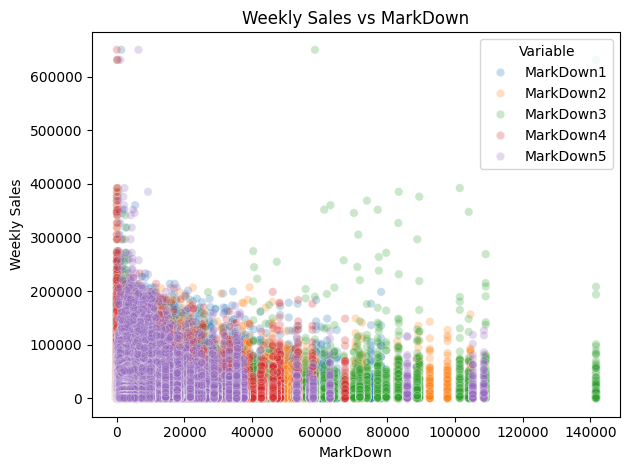

In [66]:
markdown_sales = (
    train_merged[
        ['Weekly_Sales'] +
        markdown_cols +
        [f'{col}_isna' for col in markdown_cols]
    ]
    .copy()
)

markdown_sales_long = pd.concat([
    markdown_sales.loc[
        ~markdown_sales[f'{col}_isna'],
        ['Weekly_Sales', col]
    ]
    .rename(columns={col: 'MarkDown'})
    .assign(Variable=col)
    for col in markdown_cols
])

sns.scatterplot(
    data=markdown_sales_long,
    x='MarkDown',
    y='Weekly_Sales',
    hue='Variable',
    alpha=0.25
)

plt.title('Weekly Sales vs MarkDown')
plt.xlabel('MarkDown')
plt.ylabel('Weekly Sales')
plt.tight_layout()
plt.show()

In [67]:
markdown_quantile_summary = []

for col in markdown_cols:

    # Solo observaciones donde el MarkDown estaba disponible originalmente
    data = train_merged.loc[
        ~train_merged[f'{col}_isna'],
        [col, 'Weekly_Sales']
    ].copy()

    # Dividimos el MarkDown en cuatro niveles según su intensidad
    data['MarkDown_Level'] = pd.qcut(
        data[col],
        q=4,
        labels=['Q1', 'Q2', 'Q3', 'Q4'],
        duplicates='drop'
    )

    summary = (
        data
        .groupby('MarkDown_Level', observed=True)['Weekly_Sales']
        .agg(
            Observations='count',
            Mean_Sales='mean',
            Median_Sales='median'
        )
        .reset_index()
    )

    summary['MarkDown'] = col

    markdown_quantile_summary.append(summary)

markdown_quantile_summary = pd.concat(
    markdown_quantile_summary,
    ignore_index=True
)

markdown_quantile_summary

,MarkDown_Level,Observations,Mean_Sales,Median_Sales,MarkDown
0,Q1,37727,11783.988216,4018.130,MarkDown1
1,Q2,37651,15538.784638,7430.630,MarkDown1
2,Q3,37654,17876.914552,8900.650,MarkDown1
3,Q4,37649,19671.267848,9964.350,MarkDown1
4,Q1,27823,15466.574675,7074.750,MarkDown2
5,Q2,27839,18272.483181,8904.780,MarkDown2
6,Q3,27796,17403.229409,8128.685,MarkDown2
7,Q4,27790,17063.204433,8197.075,MarkDown2
8,Q1,34276,12886.145573,5828.520,MarkDown3
9,Q2,34322,15776.143839,7541.510,MarkDown3


Aunque las correlaciones lineales entre los `MarkDown` y `Weekly_Sales` son reducidas, la agrupación de los valores promocionales en cuartiles permite observar un patrón más claro. Para `MarkDown1`, `MarkDown3`, `MarkDown4` y `MarkDown5`, tanto la media como la mediana de las ventas tienden a aumentar conforme aumenta el nivel del MarkDown. `MarkDown2` presenta un comportamiento menos consistente, sin una tendencia creciente entre todos los cuartiles.

Estos resultados muestran una asociación entre una mayor intensidad de determinados MarkDown y mayores niveles de ventas. Sin embargo, esta relación no debe interpretarse de forma causal, ya que los MarkDown pueden estar relacionados con otros factores como la tienda, el departamento o determinados periodos promocionales. Su posible utilidad predictiva se evaluará posteriormente durante el desarrollo de los modelos.

## 9. Comparación entre entrenamiento y test
El conjunto de entrenamiento contiene las ventas semanales observadas entre febrero de 2010 y octubre de 2012, mientras que el conjunto de test corresponde al periodo inmediatamente posterior, comprendido entre noviembre de 2012 y julio de 2013. Por tanto, la separación entre ambos conjuntos mantiene el orden temporal de los datos y reproduce un escenario de predicción de ventas futuras.

Ambos conjuntos comparten la misma estructura básica, formada por las variables `Store`, `Dept`, `Date` e `IsHoliday`, aunque `Weekly_Sales` únicamente está disponible en entrenamiento al constituir la variable objetivo. Las variables adicionales procedentes de features pueden asociarse a ambos periodos, si bien previamente se ha identificado una limitación de disponibilidad en CPI y Unemployment durante las últimas 13 semanas del test.

A continuación se comprueba la consistencia estructural entre ambos conjuntos, analizando el número de tiendas, departamentos y combinaciones Store–Dept, así como la posible aparición en test de categorías no observadas durante el entrenamiento.

In [68]:
# Categorías presentes en train y test
train_stores = set(train['Store'])
test_stores = set(test['Store'])

train_depts = set(train['Dept'])
test_depts = set(test['Dept'])

train_store_dept = set(zip(train['Store'], train['Dept']))
test_store_dept = set(zip(test['Store'], test['Dept']))

print('TRAIN')
print(f'Observations: {len(train):,}')
print(f'Date range: {train["Date"].min()} - {train["Date"].max()}')
print(f'Stores: {train["Store"].nunique()}')
print(f'Departments: {train["Dept"].nunique()}')
print(f'Store-Dept combinations: {len(train_store_dept)}')

print('\nTEST')
print(f'Observations: {len(test):,}')
print(f'Date range: {test["Date"].min()} - {test["Date"].max()}')
print(f'Stores: {test["Store"].nunique()}')
print(f'Departments: {test["Dept"].nunique()}')
print(f'Store-Dept combinations: {len(test_store_dept)}')

print('\nNEW IN TEST')
print(f'New stores: {test_stores - train_stores}')
print(f'New departments: {test_depts - train_depts}')
print(
    f'New Store-Dept combinations: '
    f'{len(test_store_dept - train_store_dept)}'
)

TRAIN
Observations: 421,570
Date range: 2010-02-05 00:00:00 - 2012-10-26 00:00:00
Stores: 45
Departments: 81
Store-Dept combinations: 3331

TEST
Observations: 115,064
Date range: 2012-11-02 00:00:00 - 2013-07-26 00:00:00
Stores: 45
Departments: 81
Store-Dept combinations: 3169

NEW IN TEST
New stores: set()
New departments: set()
New Store-Dept combinations: 11


In [69]:
new_store_dept = test_store_dept - train_store_dept

test_new_combinations = test[
    test[['Store', 'Dept']]
    .apply(tuple, axis=1)
    .isin(new_store_dept)
]

print(
    f'Observations belonging to unseen Store-Dept combinations: '
    f'{len(test_new_combinations):,} '
    f'({len(test_new_combinations) / len(test) * 100:.2f}%)'
)

Observations belonging to unseen Store-Dept combinations: 36 (0.03%)


La comparación estructural entre los conjuntos de entrenamiento y test muestra una elevada consistencia entre ambos. Los dos contienen las mismas 45 tiendas y los mismos 81 departamentos, por lo que no aparecen nuevas categorías individuales durante el periodo de test.

El conjunto de entrenamiento contiene 3.331 combinaciones diferentes de tienda y departamento, frente a 3.169 en test. Únicamente 11 combinaciones presentes en test no habían aparecido previamente durante el entrenamiento. Estas representan 36 observaciones, aproximadamente el 0,03 % del conjunto de test.

Por tanto, la aparición de nuevas combinaciones Store–Dept durante el horizonte de predicción es muy reducida y no supone un problema estructural relevante para el conjunto de datos. No obstante, esta circunstancia deberá tenerse en cuenta durante el desarrollo de los modelos que utilicen información específica de cada combinación tienda-departamento.

In [70]:
feature_cols = [
    'Temperature',
    'Fuel_Price',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5',
    'CPI',
    'Unemployment',
    'Size'
]

In [71]:
train_test_summary = []

for col in feature_cols:

    train_test_summary.append({
        'Variable': col,

        'Train_Mean': train_merged[col].mean(),
        'Test_Mean': test_merged[col].mean(),

        'Train_Median': train_merged[col].median(),
        'Test_Median': test_merged[col].median(),

        'Train_Min': train_merged[col].min(),
        'Test_Min': test_merged[col].min(),

        'Train_Max': train_merged[col].max(),
        'Test_Max': test_merged[col].max(),

        'Train_Missing_%': train_merged[col].isna().mean() * 100,
        'Test_Missing_%': test_merged[col].isna().mean() * 100
    })

train_test_summary = pd.DataFrame(train_test_summary)

train_test_summary

,Variable,Train_Mean,Test_Mean,Train_Median,Test_Median,Train_Min,Test_Min,Train_Max,Test_Max,Train_Missing_%,Test_Missing_%
0,Temperature,60.090059,53.941804,62.09000,54.470000,-2.060,-7.290000,100.140000,101.950000,0.0,0.00000
1,Fuel_Price,3.361027,3.581546,3.45200,3.606000,2.472,2.872000,4.468000,4.125000,0.0,0.00000
2,MarkDown1,2590.074819,7679.259430,0.00000,4828.720000,0.000,-2781.450000,88646.760000,103184.980000,0.0,0.00000
3,MarkDown2,879.974298,2805.049619,0.00000,316.880000,-265.760,-35.740000,104519.540000,71074.170000,0.0,0.00000
4,MarkDown3,468.087665,2197.811964,0.00000,60.000000,-29.100,-179.260000,141630.610000,149483.310000,0.0,0.00000
5,MarkDown4,1083.132268,2980.298267,0.00000,600.580000,0.000,0.000000,67474.850000,65344.640000,0.0,0.00000
6,MarkDown5,1662.772385,3922.681189,0.00000,2390.430000,0.000,-185.170000,108519.280000,771448.100000,0.0,0.00000
7,CPI,171.201947,176.961347,182.31878,192.304445,126.064,131.236226,227.232807,228.976456,0.0,33.16589
8,Unemployment,7.960289,6.868733,7.86600,6.806000,3.879,3.684000,14.313000,10.199000,0.0,33.16589
9,Size,136727.915739,136497.688921,140167.00000,140167.000000,34875.000,34875.000000,219622.000000,219622.000000,0.0,0.00000


In [72]:
markdown_missing_comparison = []

for col in markdown_cols:

    markdown_missing_comparison.append({
        'MarkDown': col,
        'Train_Missing_%':
            train_merged[f'{col}_isna'].mean() * 100,
        'Test_Missing_%':
            test_merged[f'{col}_isna'].mean() * 100
    })

markdown_missing_comparison = pd.DataFrame(
    markdown_missing_comparison
)

markdown_missing_comparison

,MarkDown,Train_Missing_%,Test_Missing_%
0,MarkDown1,64.257181,0.129493
1,MarkDown2,73.611025,24.879198
2,MarkDown3,67.480845,8.542203
3,MarkDown4,67.984676,11.200723
4,MarkDown5,64.079038,0.000000


La comparación de las variables explicativas muestra algunas diferencias entre los periodos de entrenamiento y test. `Temperature` y `Fuel_Price` presentan variaciones compatibles con la evolución temporal de estas variables, mientras que `Size` mantiene una distribución prácticamente idéntica al estar presentes las mismas tiendas en ambos conjuntos.

Las principales diferencias aparecen en las variables promocionales. Los `MarkDown` presentan una disponibilidad considerablemente mayor durante el periodo de test, debido en parte a que estas variables no se encuentran disponibles durante una parte importante del periodo inicial de entrenamiento. Por tanto, las diferencias observadas en sus distribuciones no deben interpretarse directamente como un cambio en la política promocional. También aparecen algunos valores fuera de los rangos observados durante el entrenamiento, especialmente en `MarkDown5`.

Por otro lado, `CPI` y `Unemployment` no presentan valores ausentes en entrenamiento, pero alcanzan un 33,17 % de valores faltantes en test. Como se observó previamente, esta ausencia se concentra en las últimas 13 semanas del horizonte de predicción y afecta simultáneamente a todas las tiendas. Esta diferencia de disponibilidad deberá tenerse en cuenta posteriormente al definir las variables utilizadas por los modelos.

En conjunto, no se observan diferencias estructurales que impidan utilizar el conjunto de entrenamiento para desarrollar los modelos, aunque existen cambios temporales y de disponibilidad que deberán considerarse durante la validación y evaluación.

## 10. Auditoría y continuidad temporal

### 10.1. Comprobaciones de las tablas integradas

In [73]:
# 1. Dimensiones, fechas y duplicados
print('TRAIN')
print(f'Shape: {train_merged.shape}')
print(f'Date range: {train_merged["Date"].min()} - {train_merged["Date"].max()}')
print(f'Duplicated rows: {train_merged.duplicated().sum()}')

print('\nTEST')
print(f'Shape: {test_merged.shape}')
print(f'Date range: {test_merged["Date"].min()} - {test_merged["Date"].max()}')
print(f'Duplicated rows: {test_merged.duplicated().sum()}')

TRAIN
Shape: (421570, 21)
Date range: 2010-02-05 00:00:00 - 2012-10-26 00:00:00
Duplicated rows: 0

TEST
Shape: (115064, 20)
Date range: 2012-11-02 00:00:00 - 2013-07-26 00:00:00
Duplicated rows: 0


In [74]:
key_cols = ['Store', 'Dept', 'Date']

print(
    'Duplicated Store-Dept-Date in train:',
    train_merged.duplicated(subset=key_cols).sum()
)

print(
    'Duplicated Store-Dept-Date in test:',
    test_merged.duplicated(subset=key_cols).sum()
)

Duplicated Store-Dept-Date in train: 0
Duplicated Store-Dept-Date in test: 0


Los conjuntos resultantes no presentan filas duplicadas. Asimismo, se comprobó la unicidad de la combinación `Store–Dept–Date`, sin encontrarse duplicados ni en entrenamiento ni en test. Esto confirma que cada observación queda identificada de forma única por una tienda, un departamento y una fecha.

El conjunto de entrenamiento contiene 421.570 observaciones y 21 variables, mientras que el conjunto de test contiene 115.064 observaciones y 20 variables. La diferencia corresponde a `Weekly_Sales`, disponible únicamente en entrenamiento al constituir la variable objetivo. Además, ambos conjuntos mantienen una separación temporal consecutiva, finalizando el periodo de entrenamiento el 26 de octubre de 2012 y comenzando el periodo de test el 2 de noviembre de 2012.

In [75]:
# 2. Valores ausentes
missing_summary = pd.DataFrame({
    'Train_Missing': train_merged.isna().sum(),
    'Test_Missing': test_merged.isna().sum()
})

missing_summary['Train_Missing_%'] = (
    missing_summary['Train_Missing'] / len(train_merged) * 100
)

missing_summary['Test_Missing_%'] = (
    missing_summary['Test_Missing'] / len(test_merged) * 100
)

missing_summary = missing_summary[
    (missing_summary['Train_Missing'] > 0) |
    (missing_summary['Test_Missing'] > 0)
]

missing_summary

,Train_Missing,Test_Missing,Train_Missing_%,Test_Missing_%
CPI,0,38162.0,0.0,33.16589
Unemployment,0,38162.0,0.0,33.16589


Tras el tratamiento de los valores ausentes de las variables `MarkDown`, las únicas variables que mantienen valores faltantes son `CPI` y `Unemployment`. Ambas se encuentran completas en el conjunto de entrenamiento, mientras que presentan 38.162 valores ausentes en test, equivalentes al 33,17 % de sus observaciones.

Como se observó previamente, estas ausencias no se distribuyen aleatoriamente, sino que se concentran en las últimas 13 semanas del horizonte de test y afectan simultáneamente a todas las tiendas. Por este motivo, no se realiza una imputación arbitraria durante el preprocesamiento. Se conservan estos valores ausentes para que su disponibilidad quede explícita al definir las variables de los modelos.

In [76]:
# 3. Valores infinitos
numeric_cols_audit = train_merged.select_dtypes(
    include='number'
).columns

print(
    'Infinite values in train:',
    np.isinf(train_merged[numeric_cols_audit]).sum().sum()
)

numeric_cols_audit_test = test_merged.select_dtypes(
    include='number'
).columns

print(
    'Infinite values in test:',
    np.isinf(test_merged[numeric_cols_audit_test]).sum().sum()
)

Infinite values in train: 0
Infinite values in test: 0


In [77]:
# 4. Tipos de datos
dtype_comparison = pd.DataFrame({
    'Train': train_merged.dtypes.astype(str),
    'Test': test_merged.dtypes.astype(str)
})

dtype_comparison

,Train,Test
CPI,float64,float64
Date,datetime64[ns],datetime64[ns]
Dept,int64,int64
Fuel_Price,float64,float64
IsHoliday,bool,bool
MarkDown1,float64,float64
MarkDown1_isna,bool,bool
MarkDown2,float64,float64
MarkDown2_isna,bool,bool
MarkDown3,float64,float64


No se detectaron valores infinitos en los conjuntos de entrenamiento ni de test. Los tipos de datos también se mantienen de forma coherente entre ambos conjuntos. Las variables numéricas conservan tipos enteros o de punto flotante según corresponda, las variables indicadoras utilizan tipo booleano y `Date` se mantiene como variable temporal.

La variable `Type` conserva su representación categórica original, ya que su codificación se realizará posteriormente en función del modelo utilizado. Del mismo modo, `Weekly_Sales` únicamente está presente en el conjunto de entrenamiento al constituir la variable objetivo.

### 10.2. Continuidad de las series tienda-departamento

Antes de exportar los datos, falta comprobar si cada serie tienda-departamento tiene una observación para todas las semanas de su periodo registrado.

Una parte importante de la información predictiva puede encontrarse en el propio historial de ventas. Por este motivo, posteriormente se incorporarán variables temporales basadas en valores anteriores de `Weekly_Sales`, como los retardos o *lags*.

No obstante, antes de construir estas variables es necesario comprobar la continuidad temporal de las series. En este conjunto de datos, cada serie temporal viene determinada por una combinación concreta de tienda y departamento (`Store–Dept`). Si alguna de estas combinaciones no dispone de observaciones para todas las semanas, la observación anterior dentro del dataset no tiene por qué corresponder necesariamente a la semana inmediatamente anterior.

Por ejemplo, ante una ausencia de varias semanas, aplicar directamente un desplazamiento de una posición podría asignar como `lag_1` una venta correspondiente realmente a dos o más semanas atrás. Esto introduciría una interpretación temporal incorrecta de la variable.

Por tanto, antes de generar los retardos de ventas se analiza la continuidad de las distintas series `Store–Dept`, identificando la presencia y magnitud de posibles huecos temporales. Este análisis permitirá posteriormente construir los *lags* respetando la distancia temporal real entre las observaciones.

In [78]:
# Número de semanas disponibles para cada combinación Store-Dept
store_dept_weeks = (
    train_merged
    .groupby(['Store', 'Dept'])
    .agg(
        First_Date=('Date', 'min'),
        Last_Date=('Date', 'max'),
        Observed_Weeks=('Date', 'nunique')
    )
    .reset_index()
)

# Número de semanas que deberían existir entre la primera
# y la última observación de cada serie
store_dept_weeks['Expected_Weeks'] = (
    (store_dept_weeks['Last_Date'] - store_dept_weeks['First_Date'])
    .dt.days // 7 + 1
)

store_dept_weeks['Missing_Weeks'] = (
    store_dept_weeks['Expected_Weeks']
    - store_dept_weeks['Observed_Weeks']
)

display(store_dept_weeks.describe())

,Store,Dept,First_Date,Last_Date,Observed_Weeks,Expected_Weeks,Missing_Weeks
count,3331.000000,3331.000000,3331,3331,3331.000000,3331.000000,3331.000000
mean,22.497448,45.715101,2010-03-07 00:12:58.144701184,2012-09-29 01:37:16.085259776,126.559592,134.865506,8.305914
min,1.000000,1.000000,2010-02-05 00:00:00,2010-02-05 00:00:00,1.000000,1.000000,0.000000
25%,11.000000,20.000000,2010-02-05 00:00:00,2012-10-26 00:00:00,143.000000,143.000000,0.000000
50%,22.000000,41.000000,2010-02-05 00:00:00,2012-10-26 00:00:00,143.000000,143.000000,0.000000
75%,33.000000,74.000000,2010-02-05 00:00:00,2012-10-26 00:00:00,143.000000,143.000000,0.000000
max,45.000000,99.000000,2012-10-05 00:00:00,2012-10-26 00:00:00,143.000000,143.000000,131.000000
std,12.833664,30.145915,NaN,NaN,40.212763,27.695219,23.619680


In [79]:
print(
    'Series Store-Dept:',
    len(store_dept_weeks)
)

print(
    'Series con semanas ausentes:',
    (store_dept_weeks['Missing_Weeks'] > 0).sum()
)

print(
    'Series completas entre su primera y última fecha:',
    (store_dept_weeks['Missing_Weeks'] == 0).sum()
)

display(
    store_dept_weeks
    .sort_values('Missing_Weeks', ascending=False)
    .head(20)
)

Series Store-Dept: 3331
Series con semanas ausentes: 605
Series completas entre su primera y última fecha: 2726


,Store,Dept,First_Date,Last_Date,Observed_Weeks,Expected_Weeks,Missing_Weeks
2638,35,78,2010-02-05,2012-09-07,5,136,131
2810,38,34,2010-02-05,2012-10-26,14,143,129
3157,43,26,2010-02-05,2012-10-19,15,142,127
1650,22,47,2010-02-19,2012-10-12,12,139,127
2806,38,29,2010-03-12,2012-10-26,12,138,126
3228,44,44,2010-03-12,2012-10-12,10,136,126
2546,34,47,2010-02-19,2012-09-28,12,137,125
2286,30,99,2010-02-05,2012-09-07,11,136,125
2819,38,55,2010-04-09,2012-10-12,8,132,124
2961,40,47,2010-02-12,2012-09-21,14,137,123


In [80]:
# Distribución del número de semanas ausentes
store_dept_weeks['Missing_Weeks'].value_counts().sort_index().head(20)

,count
Missing_Weeks,
0,2726
1,24
2,22
3,14
4,18
5,11
6,8
7,12
8,9


In [81]:
# Porcentaje de series según el número de semanas ausentes
(
    store_dept_weeks['Missing_Weeks']
    .value_counts(normalize=True)
    .sort_index()
    .head(20)
    .mul(100)
    .round(2)
)

,proportion
Missing_Weeks,
0,81.84
1,0.72
2,0.66
3,0.42
4,0.54
5,0.33
6,0.24
7,0.36
8,0.27


In [82]:
# Agrupamos las series según su número de semanas ausentes
missing_week_ranges = pd.cut(
    store_dept_weeks['Missing_Weeks'],
    bins=[-1, 0, 5, 20, 50, 100, float('inf')],
    labels=[
        '0',
        '1-5',
        '6-20',
        '21-50',
        '51-100',
        '>100'
    ]
)

missing_week_summary = (
    missing_week_ranges
    .value_counts()
    .sort_index()
    .to_frame('Series')
)

missing_week_summary['Percentage_%'] = (
    missing_week_summary['Series']
    / len(store_dept_weeks)
    * 100
)

display(missing_week_summary)

,Series,Percentage_%
Missing_Weeks,,
0,2726,81.837286
1-5,89,2.671870
6-20,118,3.542480
21-50,161,4.833383
51-100,172,5.163615
>100,65,1.951366


**Continuidad temporal de las series `Store-Dept`**

Se identificaron 3.331 combinaciones distintas de tienda y departamento. De ellas, aproximadamente el 81,84 % presentan observaciones semanales continuas entre su primera y última aparición, mientras que el 18,16 % contiene al menos una semana ausente.

Las discontinuidades no corresponden únicamente a pequeños huecos aislados. Entre las series discontinuas, aproximadamente dos tercios presentan más de 20 semanas ausentes, existiendo incluso combinaciones que aparecen únicamente unas pocas veces a lo largo de todo el periodo analizado.

Este comportamiento debe tenerse en cuenta durante la construcción de variables temporales. En particular, los retardos de ventas no deben calcularse únicamente a partir de la posición de las observaciones, ya que la fila anterior no siempre representa la semana inmediatamente anterior. Por este motivo, los lags se construirán considerando explícitamente la diferencia temporal entre fechas.

La continuidad se mide entre la primera y la última fecha de cada serie: no implica que todas cubran el periodo completo de entrenamiento. El número total de semanas ausentes tampoco indica que formen un único hueco consecutivo. En este notebook solo se diagnostican las ausencias; no se añaden semanas ni se reconstruyen ventas.

## 11. Exportación y continuación del trabajo

Guardamos `train_merged` y `test_merged` en formato Parquet para mantener los tipos de datos y utilizarlos en el siguiente notebook. Las tablas conservan todas las observaciones originales, las variables integradas y los indicadores de ausencia de los `MarkDown`.

In [83]:
# =============================================================================
# VERIFICACIÓN DE LOS DATASETS UTILIZADOS Y CONSERVADOS EN DRIVE
# =============================================================================
# Los parquet ya se han cargado o regenerado antes de la exploración para que
# todos los análisis posteriores utilicen exactamente esos mismos datos.
assert PROCESSED_TRAIN.exists() and PROCESSED_TEST.exists()
print('Datasets utilizados por el EDA y disponibles para ModeloPredictivo:')
print(' -', PROCESSED_TRAIN)
print(' -', PROCESSED_TEST)
print('TRAIN =', TRAIN)


Datasets utilizados por el EDA y disponibles para ModeloPredictivo:
 - /content/drive/MyDrive/TFM/data/processed/train_processed.parquet
 - /content/drive/MyDrive/TFM/data/processed/test_processed.parquet
TRAIN = True


In [84]:
# Alternativa csv
# train_merged.to_csv(
#     'train_processed.csv',
#     index=False
# )

# test_merged.to_csv(
#     'test_processed.csv',
#     index=False
# )

Los archivos `train_processed.parquet` y `test_processed.parquet` quedan guardados en `/content/drive/MyDrive/TFM/data/processed`.

La exploración deja tres cuestiones especialmente importantes para continuar: la estacionalidad de las ventas, las diferencias de escala entre tiendas y departamentos y la disponibilidad desigual de parte del historial y de las variables explicativas.

El siguiente notebook parte de estas tablas para definir la partición temporal de entrenamiento y validación, construir variables de calendario y retardos, y comparar los primeros modelos con una referencia estacional. El conjunto de test no contiene `Weekly_Sales`, por lo que sus ventas no pueden evaluarse directamente en estos archivos.